In [ ]:
!pip install -q earthaccess xarray netCDF4 h5netcdf \
    pandas numpy matplotlib scipy \
    geopandas rasterio rioxarray \
    regionmask shapely pymannkendall h5py

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip check

No broken requirements found.


In [ ]:
!pip install -q --upgrade \
    "fsspec[http]==2025.12.0" \
    "gcsfs==2025.12.0" \
    "s3fs==2025.12.0" \
    "jedi"

In [ ]:
import fsspec
import gcsfs
import s3fs
import jedi

print("fsspec:", fsspec.__version__)
print("gcsfs:", gcsfs.__version__)
print("s3fs:", s3fs.__version__)
print("jedi:", jedi.__version__)

!pip check

fsspec: 2025.12.0
gcsfs: 2025.12.0
s3fs: 2025.12.0
jedi: 0.20.1
No broken requirements found.


In [ ]:

import earthaccess
import xarray as xr
import netCDF4
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import rioxarray
import pymannkendall
import scipy
import statsmodels
import cartopy

print("¡Todas las librerías se importaron correctamente!")
print("Xarray:", xr.__version__)


ModuleNotFoundError: No module named 'cartopy'

In [ ]:
import earthaccess

# Solicita tus credenciales de NASA Earthdata
auth = earthaccess.login()

print("Estado de autenticación:", auth.authenticated)


Enter your Earthdata Login username: luvii_yvv
Enter your Earthdata password: ··········
Estado de autenticación: True


In [ ]:

import earthaccess

busquedas = {
    "Clorofila-a Aqua MODIS": "Aqua MODIS chlorophyll monthly Level 3",
    "Temperatura superficial del mar Aqua MODIS": "Aqua MODIS sea surface temperature monthly Level 3",
    "Precipitación GPM IMERG": "GPM IMERG monthly precipitation Final"
}

resultados = {}

for nombre, palabra_clave in busquedas.items():

    print("\n" + "=" * 65)
    print(nombre)
    print("=" * 65)

    colecciones = earthaccess.search_datasets(
        keyword=palabra_clave,
        count=10
    )

    resultados[nombre] = colecciones

    for i, coleccion in enumerate(colecciones, start=1):
        print(f"\nResultado {i}:")
        print(coleccion.summary)



Clorofila-a Aqua MODIS

Resultado 1:
{'short-name': '0875b4675f1e46ebadb526e0b95505c5', 'concept-id': 'C3327359430-FEDEO', 'version': 'NA', 'file-type': '', 'get-data': ['https://fedeo-client.ceos.org?uid=0875b4675f1e46ebadb526e0b95505c5', 'https://fedeo.ceos.org/collections/series/items/0875b4675f1e46ebadb526e0b95505c5?httpAccept=application/vnd.iso.19139-2%2Bxml']}

Resultado 2:
{'short-name': '474ac06235e54e6cb0ec6eed635e1213', 'concept-id': 'C3327359219-FEDEO', 'version': 'NA', 'file-type': '', 'get-data': ['https://fedeo-client.ceos.org?uid=474ac06235e54e6cb0ec6eed635e1213', 'https://fedeo.ceos.org/collections/series/items/474ac06235e54e6cb0ec6eed635e1213?httpAccept=application/vnd.iso.19139-2%2Bxml']}

Resultado 3:
{'short-name': '690fdf8f229c4d04a2aa68de67beb733', 'concept-id': 'C3327359002-FEDEO', 'version': 'NA', 'file-type': '', 'get-data': ['https://fedeo-client.ceos.org?uid=690fdf8f229c4d04a2aa68de67beb733', 'https://fedeo.ceos.org/collections/series/items/690fdf8f229c4d04

In [ ]:
productos = {
    "Temperatura": {
        "short_name": "MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0",
        "version": "2019.0"
    },
    "Precipitacion": {
        "short_name": "GPM_3IMERGM",
        "version": "07"
    }
}

In [ ]:

import earthaccess

# Buscar clorofila-a mensual de Aqua MODIS, resolución de 4 km
resultados_chl = earthaccess.search_data(
    short_name="MODISA_L3m_CHL",
    version="2022.0",
    temporal=("2003-01-01", "2025-12-31"),
    bounding_box=(-98, 18, -80, 31),
    granule_name="*.MO.CHL.chlor_a.4km*"
)

print("Granules encontrados:", len(resultados_chl))

# Mostrar algunos resultados sin descargarlos
for archivo in resultados_chl[:10]:
    print(archivo)


Granules encontrados: 329
Collection: {'ShortName': 'MODISA_L3m_CHL', 'Version': '2022.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'SouthBoundingCoordinate': -90, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 90, 'WestBoundingCoordinate': -180}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2003-01-01T00:00:00Z', 'EndingDateTime': '2003-01-31T23:59:59Z'}}
Size(MB): 55.545515060424805
Data: ['https://obdaac-tea.earthdatacloud.nasa.gov/ob-cumulus-prod-public/AQUA_MODIS.20030101_20030131.L3m.MO.CHL.chlor_a.4km.nc']
Collection: {'Version': '2022.0', 'ShortName': 'MODISA_L3m_CHL'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'EastBoundingCoordinate': 180, 'SouthBoundingCoordinate': -90, 'NorthBoundingCoordinate': 90, 'WestBoundingCoordinate': -180}]}}}
Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2003-02-28T23:59:59Z', 'BeginningDateTime': '2003-02-01T00:00:00Z'}}
Size

In [ ]:

print("Total de granules:", len(resultados_chl))

print("\nÚltimos 10 resultados:")
for archivo in resultados_chl[-10:]:
    print(archivo)


Total de granules: 329

Últimos 10 resultados:
Collection: {'ShortName': 'MODISA_L3m_CHL', 'Version': '2022.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'NorthBoundingCoordinate': 90, 'SouthBoundingCoordinate': -90, 'EastBoundingCoordinate': 180, 'WestBoundingCoordinate': -180}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2025-07-01T00:00:00Z', 'EndingDateTime': '2025-07-31T23:59:59Z'}}
Size(MB): 42.96810722351074
Data: ['https://obdaac-tea.earthdatacloud.nasa.gov/ob-cumulus-prod-public/AQUA_MODIS.20250701_20250731.L3m.MO.CHL.chlor_a.4km.nc']
Collection: {'Version': '2022.0', 'ShortName': 'MODISA_L3m_CHL'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'NorthBoundingCoordinate': 90, 'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -90, 'EastBoundingCoordinate': 180}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2025-08-01T00:00:00Z', 'EndingDateTime': '2025-08-

In [ ]:

import re
from collections import Counter

nombres = []

for archivo in resultados_chl:
    texto = str(archivo)
    coincidencia = re.search(
        r"AQUA_MODIS\.(\d{8})_(\d{8})\.L3m\.MO\.CHL\.chlor_a\.4km\.nc",
        texto
    )
    if coincidencia:
        nombres.append(coincidencia.group(0))

conteo = Counter(nombres)

print("Archivos con nombre válido:", len(nombres))
print("Archivos únicos:", len(set(nombres)))
print("Nombres repetidos:", sum(v > 1 for v in conteo.values()))
print("Ejemplos repetidos:", [n for n, v in conteo.items() if v > 1][:10])


Archivos con nombre válido: 329
Archivos únicos: 276
Nombres repetidos: 53
Ejemplos repetidos: ['AQUA_MODIS.20210701_20210731.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20210801_20210831.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20210901_20210930.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20211001_20211031.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20211101_20211130.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20211201_20211231.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20220101_20220131.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20220201_20220228.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20220301_20220331.L3m.MO.CHL.chlor_a.4km.nc', 'AQUA_MODIS.20220401_20220430.L3m.MO.CHL.chlor_a.4km.nc']


In [ ]:

import pandas as pd
import re

# Extraer la fecha inicial de cada archivo único
fechas = [
    re.search(r"\.(\d{8})_", nombre).group(1)
    for nombre in set(nombres)
]

meses_encontrados = pd.PeriodIndex(
    pd.to_datetime(fechas, format="%Y%m%d"),
    freq="M"
).unique().sort_values()

# Crear la lista de los 276 meses esperados
meses_esperados = pd.period_range(
    start="2003-01",
    end="2025-12",
    freq="M"
)

faltantes = meses_esperados.difference(meses_encontrados)
sobrantes = meses_encontrados.difference(meses_esperados)

print("Meses encontrados:", len(meses_encontrados))
print("Meses esperados:", len(meses_esperados))
print("Meses faltantes:", list(faltantes))
print("Meses fuera del periodo:", list(sobrantes))

if len(faltantes) == 0 and len(sobrantes) == 0:
    print("\n¡Serie mensual completa!")
else:
    print("\nHay que revisar la cobertura temporal.")


Meses encontrados: 276
Meses esperados: 276
Meses faltantes: []
Meses fuera del periodo: []

¡Serie mensual completa!


In [ ]:

import re

# Conservar un solo registro por nombre de archivo
granules_unicos = {}

for granule in resultados_chl:
    texto = str(granule)

    coincidencia = re.search(
        r"AQUA_MODIS\.\d{8}_\d{8}\.L3m\.MO\.CHL\.chlor_a\.4km\.nc",
        texto
    )

    if coincidencia:
        nombre = coincidencia.group(0)
        if nombre not in granules_unicos:
            granules_unicos[nombre] = granule

resultados_unicos = list(granules_unicos.values())

print("Granules originales:", len(resultados_chl))
print("Granules únicos:", len(resultados_unicos))


Granules originales: 329
Granules únicos: 276


In [ ]:
# Prueba 2003
archivo_prueba = next(
    g for g in resultados_unicos
    if "20030101_20030131" in str(g)
)

print(archivo_prueba)


Collection: {'ShortName': 'MODISA_L3m_CHL', 'Version': '2022.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'SouthBoundingCoordinate': -90, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 90, 'WestBoundingCoordinate': -180}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2003-01-01T00:00:00Z', 'EndingDateTime': '2003-01-31T23:59:59Z'}}
Size(MB): 55.545515060424805
Data: ['https://obdaac-tea.earthdatacloud.nasa.gov/ob-cumulus-prod-public/AQUA_MODIS.20030101_20030131.L3m.MO.CHL.chlor_a.4km.nc']


In [ ]:
import earthaccess
import xarray as xr

archivos_abiertos = earthaccess.open([archivo_prueba])

print("Archivos abiertos:", len(archivos_abiertos))


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Archivos abiertos: 1


In [ ]:

ds = xr.open_dataset(archivos_abiertos[0])

print(ds)
print("\nVariables disponibles:")
print(list(ds.data_vars))


<xarray.Dataset> Size: 149MB
Dimensions:  (lat: 4320, lon: 8640, rgb: 3, eightbitcolor: 256)
Coordinates:
  * lat      (lat) float32 17kB 89.98 89.94 89.9 89.85 ... -89.9 -89.94 -89.98
  * lon      (lon) float32 35kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Dimensions without coordinates: rgb, eightbitcolor
Data variables:
    chlor_a  (lat, lon) float32 149MB ...
    palette  (rgb, eightbitcolor) uint8 768B ...
Attributes: (12/62)
    product_name:                     AQUA_MODIS.20030101_20030131.L3m.MO.CHL...
    instrument:                       MODIS
    title:                            MODISA Level-3 Standard Mapped Image
    project:                          Ocean Biology Processing Group (NASA/GS...
    platform:                         Aqua
    source:                           satellite observations from MODIS-Aqua
    ...                               ...
    cdm_data_type:                    grid
    keywords:                         Earth Science > Oceans > Ocean Chemist

In [ ]:
# Revisar los datos/valores de clorofila

print("Atributos de chlor_a:")
for clave, valor in ds["chlor_a"].attrs.items():
    print(f"{clave}: {valor}")

print("\nEstadísticas iniciales:")
print("Mínimo:", float(ds["chlor_a"].min(skipna=True)))
print("Máximo:", float(ds["chlor_a"].max(skipna=True)))
print("Media:", float(ds["chlor_a"].mean(skipna=True)))

print("\nCoordenadas:")
print("Latitud:", float(ds.lat.min()), "a", float(ds.lat.max()))
print("Longitud:", float(ds.lon.min()), "a", float(ds.lon.max()))



Atributos de chlor_a:
long_name: Chlorophyll Concentration, OCI Algorithm
units: mg m^-3
standard_name: mass_concentration_of_chlorophyll_in_sea_water
valid_min: 0.0010000000474974513
valid_max: 100.0
reference: Hu, C., Lee Z., and Franz, B.A. (2012). Chlorophyll-a algorithms for oligotrophic oceans: A novel approach based on three-band reflectance difference, J. Geophys. Res., 117, C01011, doi:10.1029/2011JC007395.
display_scale: log
display_min: 0.009999999776482582
display_max: 20.0

Estadísticas iniciales:
Mínimo: 0.0031629675067961216
Máximo: 86.35630798339844
Media: 0.27315422892570496

Coordenadas:
Latitud: -89.97917175292969 a 89.97916412353516
Longitud: -179.9791717529297 a 179.9791717529297


In [ ]:
# Recortar al Golfo de México

# Límites geográficos de prueba
lat_min, lat_max = 18, 31
lon_min, lon_max = -98, -80

# Recortar la región
chl_golfo = ds["chlor_a"].sel(
    lat=slice(lat_max, lat_min),
    lon=slice(lon_min, lon_max)
)

print(chl_golfo)
print("\nDimensiones del recorte:", chl_golfo.shape)


<xarray.DataArray 'chlor_a' (lat: 312, lon: 432)> Size: 539kB
array([[     nan,      nan,      nan, ..., 0.625274, 0.508461, 0.520203],
       [     nan,      nan,      nan, ..., 0.580772, 0.479162, 0.432249],
       [     nan,      nan,      nan, ..., 0.565775, 0.48679 , 0.459313],
       ...,
       [     nan,      nan,      nan, ..., 0.122868, 0.126915, 0.129535],
       [     nan,      nan,      nan, ..., 0.118391, 0.117981, 0.117535],
       [     nan,      nan,      nan, ..., 0.13056 , 0.128803, 0.125326]],
      shape=(312, 432), dtype=float32)
Coordinates:
  * lat      (lat) float32 1kB 30.98 30.94 30.9 30.85 ... 18.15 18.1 18.06 18.02
  * lon      (lon) float32 2kB -97.98 -97.94 -97.9 ... -80.1 -80.06 -80.02
Attributes:
    long_name:      Chlorophyll Concentration, OCI Algorithm
    units:          mg m^-3
    standard_name:  mass_concentration_of_chlorophyll_in_sea_water
    valid_min:      0.001
    valid_max:      100.0
    reference:      Hu, C., Lee Z., and Franz, B.A. (

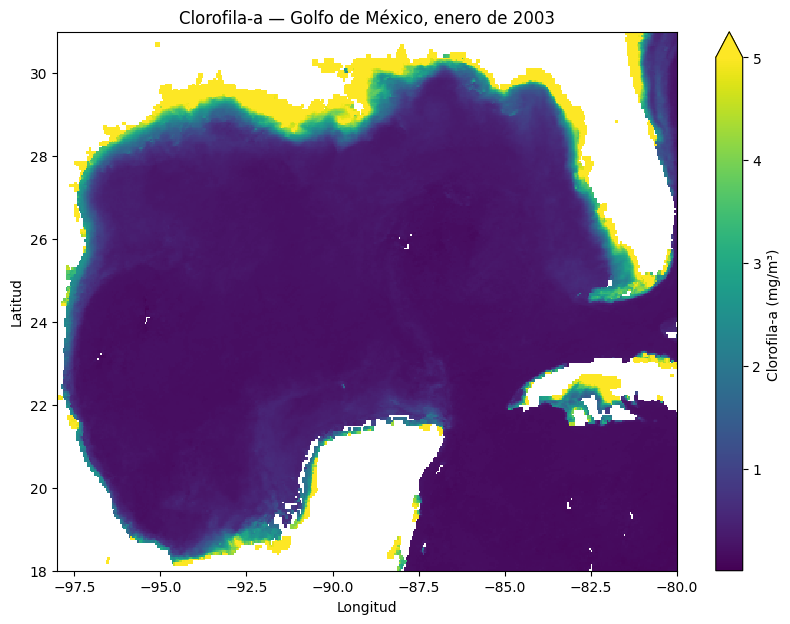

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

chl_golfo.plot(
    x="lon",
    y="lat",
    cmap="viridis",
    vmin=0.01,
    vmax=5,
    cbar_kwargs={"label": "Clorofila-a (mg/m³)"}
)

plt.title("Clorofila-a — Golfo de México, enero de 2003")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()


In [ ]:

import numpy as np
import pandas as pd

# Convertir a arreglo numérico
valores = chl_golfo.values

# Máscara de valores válidos
validos = (
    np.isfinite(valores) &
    (valores >= 0.001) &
    (valores <= 100)
)

# Estadísticas de calidad
total = valores.size
con_datos = int(np.isfinite(valores).sum())
validos_rango = int(validos.sum())
faltantes = total - con_datos
fuera_rango = con_datos - validos_rango

resumen_qc = pd.DataFrame({
    "Indicador": [
        "Píxeles totales",
        "Píxeles con datos",
        "Píxeles faltantes (NaN)",
        "Píxeles dentro del rango válido",
        "Píxeles fuera del rango válido"
    ],
    "Cantidad": [
        total,
        con_datos,
        faltantes,
        validos_rango,
        fuera_rango
    ],
    "Porcentaje": [
        100,
        100 * con_datos / total,
        100 * faltantes / total,
        100 * validos_rango / total,
        100 * fuera_rango / total
    ]
})

display(resumen_qc.round(2))


,Indicador,Cantidad,Porcentaje
0,Píxeles totales,134784,100.0
1,Píxeles con datos,103115,76.5
2,Píxeles faltantes (NaN),31669,23.5
3,Píxeles dentro del rango válido,103115,76.5
4,Píxeles fuera del rango válido,0,0.0


In [ ]:

chl_limpia = chl_golfo.where(validos)

print("Estadísticas después del control de calidad:")
print("Media:", float(chl_limpia.mean(skipna=True)))
print("Mediana:", float(chl_limpia.median(skipna=True)))
print("Desviación estándar:", float(chl_limpia.std(skipna=True)))
print("Mínimo:", float(chl_limpia.min(skipna=True)))
print("Máximo:", float(chl_limpia.max(skipna=True)))


Estadísticas después del control de calidad:
Media: 0.9531210660934448
Mediana: 0.2668750286102295
Desviación estándar: 2.5465025901794434
Mínimo: 0.052256662398576736
Máximo: 82.36874389648438


# **¿Dónde están los pixeles disponibles?**

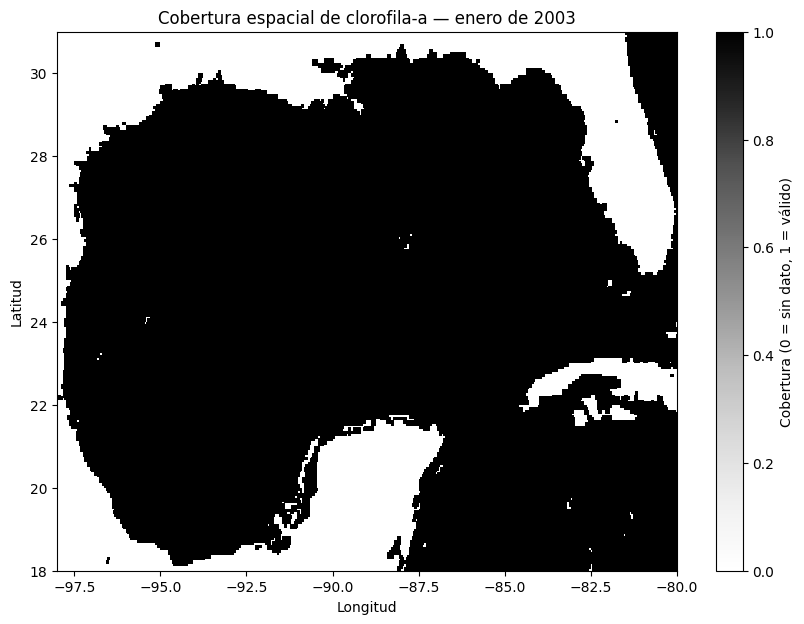

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# 1 = píxel válido; 0 = píxel faltante o inválido
cobertura = np.isfinite(chl_limpia).astype(int)

plt.figure(figsize=(10, 7))

cobertura.plot(
    x="lon",
    y="lat",
    cmap="Greys",
    vmin=0,
    vmax=1,
    add_colorbar=True,
    cbar_kwargs={"label": "Cobertura (0 = sin dato, 1 = válido)"}
)

plt.title("Cobertura espacial de clorofila-a — enero de 2003")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()


In [ ]:

estadisticas_enero = pd.DataFrame([{
    "fecha": "2003-01-01",
    "media_mg_m3": float(chl_limpia.mean(skipna=True)),
    "mediana_mg_m3": float(chl_limpia.median(skipna=True)),
    "desviacion_std_mg_m3": float(chl_limpia.std(skipna=True)),
    "minimo_mg_m3": float(chl_limpia.min(skipna=True)),
    "maximo_mg_m3": float(chl_limpia.max(skipna=True)),
    "pixeles_validos": int(validos.sum()),
    "cobertura_porcentaje": 100 * float(validos.sum()) / total
}])

display(estadisticas_enero.round(4))


,fecha,media_mg_m3,mediana_mg_m3,desviacion_std_mg_m3,minimo_mg_m3,maximo_mg_m3,pixeles_validos,cobertura_porcentaje
0,2003-01-01,0.9531,0.2669,2.5465,0.0523,82.3687,103115,76.5039


# **Máscara**
Límite del Golfo: un polígono que delimite la región marina de interés.



Máscara terrestre: excluir los píxeles que correspondan a tierra.

In [ ]:
!pip install regionmask shapely

In [ ]:
import regionmask
import geopandas as gpd
import shapely

print("regionmask:", regionmask.__version__)
print("geopandas:", gpd.__version__)
print("shapely:", shapely.__version__)


regionmask: 0.13.0
geopandas: 1.2.0
shapely: 2.2.0


In [ ]:
# Cargar límites terrestres

import regionmask
import geopandas as gpd
import shapely
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Cargar la máscara terrestre de Natural Earth
tierra = regionmask.defined_regions.natural_earth_v5_0_0.land_10

print("Límites terrestres cargados correctamente.")
print(tierra)


Límites terrestres cargados correctamente.
<regionmask.Regions 'Natural Earth: landmask 10m'>
Source:   http://www.naturalearthdata.com
overlap:  False

Regions:
0 lnd land

[1 regions]


In [ ]:

from shapely.geometry import Polygon

# Polígono preliminar del Golfo de México
coordenadas_golfo = [
    (-98.0, 31.0),
    (-80.0, 31.0),
    (-80.0, 25.0),
    (-81.0, 24.8),
    (-82.0, 24.7),
    (-83.0, 24.6),
    (-84.5, 22.5),
    (-85.0, 21.8),
    (-86.7, 21.2),
    (-87.5, 21.5),
    (-90.0, 21.5),
    (-92.0, 18.0),
    (-98.0, 18.0),
    (-98.0, 31.0)
]

poligono_golfo = Polygon(coordenadas_golfo)

print("¿Polígono válido?", poligono_golfo.is_valid)
print("Área geométrica:", poligono_golfo.area)


¿Polígono válido? True
Área geométrica: 182.42


In [ ]:

import geopandas as gpd

# Obtener las geometrías del objeto de regiones
geometrias_tierra = tierra.polygons

# Convertirlas en GeoDataFrame
gdf_tierra = gpd.GeoDataFrame(
    geometry=geometrias_tierra,
    crs="EPSG:4326"
)

print(gdf_tierra.head())
print("Tipo:", type(gdf_tierra))
print("Sistema de coordenadas:", gdf_tierra.crs)


                                            geometry
0  MULTIPOLYGON (((-0.00029 -71.49903, 0.01555 -7...
Tipo: <class 'geopandas.geodataframe.GeoDataFrame'>
Sistema de coordenadas: EPSG:4326


In [ ]:

mascara_tierra = regionmask.mask_geopandas(
    gdf_tierra,
    lon_or_obj=chl_golfo.lon,
    lat=chl_golfo.lat
)

es_tierra = mascara_tierra.notnull().values

# Combinar el polígono del Golfo con la máscara terrestre
mascara_oceano = dentro_golfo & (~es_tierra)

mascara_golfo = xr.DataArray(
    mascara_oceano,
    coords={"lat": chl_golfo.lat, "lon": chl_golfo.lon},
    dims=("lat", "lon"),
    name="mascara_oceano"
)

chl_golfo_oceano = chl_limpia.where(mascara_golfo)

print("Píxeles oceánicos:", int(mascara_golfo.sum()))
print("Píxeles con clorofila válida:", int(chl_golfo_oceano.count()))


NameError: name 'dentro_golfo' is not defined

In [ ]:

plt.figure(figsize=(10, 7))

mascara_golfo.plot(
    cmap="Greys",
    add_colorbar=False
)

plt.title("Máscara oceánica preliminar — Golfo de México")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()


NameError: name 'mascara_golfo' is not defined

<Figure size 1000x700 with 0 Axes>

In [ ]:

print("Coordenadas del polígono actual:")
for i, punto in enumerate(coordenadas_golfo):
    print(f"{i}: longitud={punto[0]}, latitud={punto[1]}")


Coordenadas del polígono actual:
0: longitud=-98.0, latitud=31.0
1: longitud=-80.0, latitud=31.0
2: longitud=-80.0, latitud=25.0
3: longitud=-81.0, latitud=24.8
4: longitud=-82.0, latitud=24.7
5: longitud=-83.0, latitud=24.6
6: longitud=-84.5, latitud=22.5
7: longitud=-85.0, latitud=21.8
8: longitud=-86.7, latitud=21.2
9: longitud=-87.5, latitud=21.5
10: longitud=-90.0, latitud=21.5
11: longitud=-92.0, latitud=18.0
12: longitud=-98.0, latitud=18.0
13: longitud=-98.0, latitud=31.0


In [ ]:
# Prueba capa 2


import geopandas as gpd

url_gom = (
    "https://services1.arcgis.com/qr14biwnHA6Vis6l/"
    "arcgis/rest/services/GoM_Region_GSHHS/FeatureServer/2/"
    "query?where=1%3D1&outFields=*&returnGeometry=true"
    "&outSR=4326&f=geojson"
)

gdf_golfo = gpd.read_file(url_gom)

print("Tipo de geometría:", gdf_golfo.geom_type.unique())
print("Sistema de coordenadas:", gdf_golfo.crs)
print("Número de elementos:", len(gdf_golfo))
print(gdf_golfo.head())


Tipo de geometría: ['MultiPolygon']
Sistema de coordenadas: EPSG:4326
Número de elementos: 1
   objectid  fid_globe_  id region  fid_gshhs_ id_1  level_ source  parent_id  \
0         1          -1   0                 -1            0                 0   

   sibling_id  ...  fid_gshhs1  id_12 level_1  source_1 parent_i_1  \
0           0  ...          -1              0                    0   

   sibling__1  area_1   Shape__Area  Shape__Length  \
0           0       0  1.968400e+12   3.589978e+07   

                                            geometry  
0  MULTIPOLYGON (((-86.98747 20.71249, -86.98436 ...  

[1 rows x 21 columns]


Text(141.43697563789425, 0.5, 'Latitud')

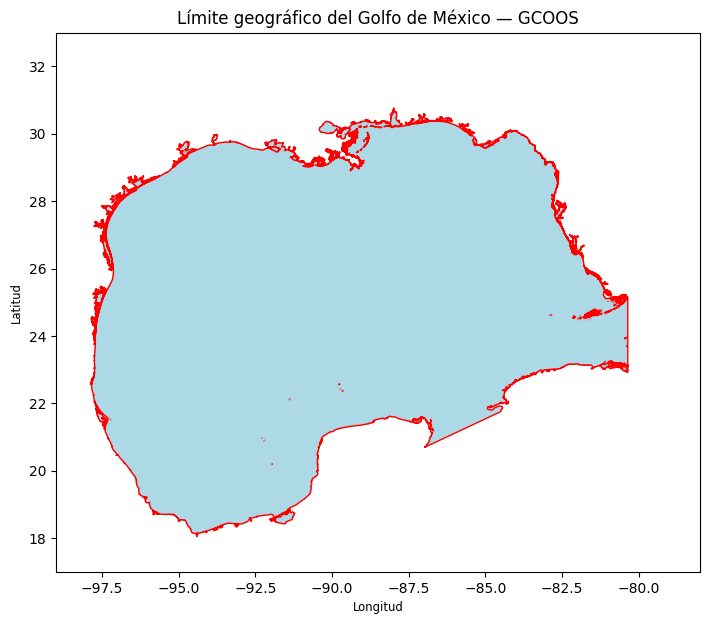

In [ ]:

ax = gdf_golfo.plot(
    figsize=(10, 7),
    edgecolor="red",
    facecolor="lightblue"
)

ax.set_xlim(-99, -78)
ax.set_ylim(17, 33)
ax.set_title("Límite geográfico del Golfo de México — GCOOS")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")


In [ ]:

print("Número de elementos:", len(gdf_golfo))
print("Tipo de geometrías:", gdf_golfo.geom_type.value_counts())
print("CRS:", gdf_golfo.crs)
print("Geometrías válidas:", gdf_golfo.geometry.is_valid.all())
print("Límites:", gdf_golfo.total_bounds)

# Revisar atributos disponibles
print("\nColumnas:")
print(gdf_golfo.columns.tolist())

# Revisar información de cada elemento
display(gdf_golfo.drop(columns="geometry").head())


Número de elementos: 1
Tipo de geometrías: MultiPolygon    1
Name: count, dtype: int64
CRS: EPSG:4326
Geometrías válidas: False
Límites: [-97.891111  18.060806 -80.377     30.775056]

Columnas:
['objectid', 'fid_globe_', 'id', 'region', 'fid_gshhs_', 'id_1', 'level_', 'source', 'parent_id', 'sibling_id', 'area', 'fid_gshhs1', 'id_12', 'level_1', 'source_1', 'parent_i_1', 'sibling__1', 'area_1', 'Shape__Area', 'Shape__Length', 'geometry']


,objectid,fid_globe_,id,region,fid_gshhs_,id_1,level_,source,parent_id,sibling_id,area,fid_gshhs1,id_12,level_1,source_1,parent_i_1,sibling__1,area_1,Shape__Area,Shape__Length
0,1,-1,0,,-1,,0,,0,0,0,-1,,0,,0,0,0,1.968400e+12,3.589978e+07


In [ ]:

from shapely.ops import unary_union
import shapely
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Unir los elementos de la capa en una sola geometría
geometria_golfo = unary_union(gdf_golfo.geometry)

# Comprobar geometría
print("Geometría válida:", geometria_golfo.is_valid)
print("Tipo:", geometria_golfo.geom_type)

# Crear cuadrícula de coordenadas del producto MODIS
lon_grid, lat_grid = np.meshgrid(
    chl_golfo.lon.values,
    chl_golfo.lat.values
)

# Identificar los píxeles dentro de la geometría
dentro_golfo_gcoos = shapely.contains_xy(
    geometria_golfo,
    lon_grid,
    lat_grid
)

# Crear DataArray de la máscara
mascara_golfo_gcoos = xr.DataArray(
    dentro_golfo_gcoos,
    coords={
        "lat": chl_golfo.lat,
        "lon": chl_golfo.lon
    },
    dims=("lat", "lon"),
    name="mascara_golfo_gcoos"
)

# Aplicar a los datos de clorofila ya filtrados
chl_golfo_final = chl_limpia.where(mascara_golfo_gcoos)

print("Píxeles dentro de la región:", int(mascara_golfo_gcoos.sum()))
print("Píxeles con clorofila válida:", int(chl_golfo_final.count()))


Geometría válida: True
Tipo: MultiPolygon
Píxeles dentro de la región: 83076
Píxeles con clorofila válida: 82416


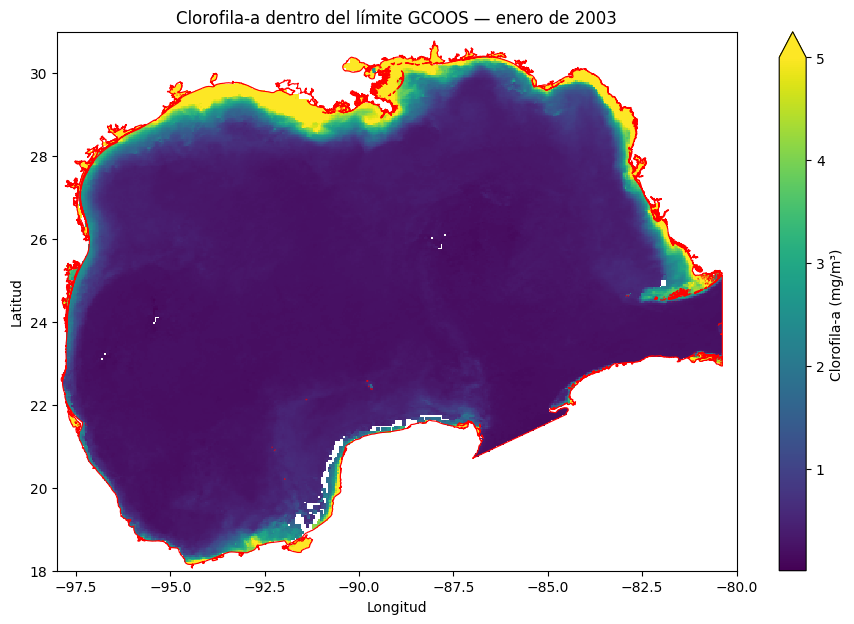

In [ ]:

fig, ax = plt.subplots(figsize=(11, 7))

chl_golfo_final.plot(
    ax=ax,
    x="lon",
    y="lat",
    cmap="viridis",
    vmin=0.01,
    vmax=5,
    cbar_kwargs={"label": "Clorofila-a (mg/m³)"}
)

gdf_golfo.boundary.plot(
    ax=ax,
    color="red",
    linewidth=0.8
)

ax.set_title("Clorofila-a dentro del límite GCOOS — enero de 2003")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.show()


In [ ]:
# Reparar geometia

import geopandas as gpd
import shapely
import numpy as np
import xarray as xr

# 1. Reparar la geometría original
geometrias_reparadas = gdf_golfo.geometry.make_valid()

# 2. Unir los elementos geográficos
geometria_golfo = shapely.union_all(
    geometrias_reparadas.array
)

# 3. Asegurar validez de la geometría final
geometria_golfo = shapely.make_valid(geometria_golfo)

print("Geometría final válida:", geometria_golfo.is_valid)
print("Tipo:", geometria_golfo.geom_type)
print("Área:", geometria_golfo.area)

# 4. Crear nuevamente la máscara
lon_grid, lat_grid = np.meshgrid(
    chl_golfo.lon.values,
    chl_golfo.lat.values
)

dentro_golfo = shapely.contains_xy(
    geometria_golfo,
    lon_grid,
    lat_grid
)

mascara_golfo = xr.DataArray(
    dentro_golfo,
    coords={
        "lat": chl_golfo.lat,
        "lon": chl_golfo.lon
    },
    dims=("lat", "lon"),
    name="mascara_golfo"
)

# 5. Aplicar máscara a la clorofila limpia
chl_golfo_final = chl_limpia.where(mascara_golfo)

# 6. Estadísticas
print("\nRESULTADOS FINALES")
print("Píxeles dentro del Golfo:",
      int(mascara_golfo.sum()))

print("Píxeles con clorofila válida:",
      int(chl_golfo_final.count()))

print("Píxeles sin datos:",
      int(mascara_golfo.sum()) -
      int(chl_golfo_final.count()))


Geometría final válida: True
Tipo: MultiPolygon
Área: 143.85306300349671

RESULTADOS FINALES
Píxeles dentro del Golfo: 82838
Píxeles con clorofila válida: 82227
Píxeles sin datos: 611


Los 276 meses completos son una excelente base para el análisis. Debemos conservar la misma delimitación espacial durante todo el periodo para que las comparaciones sean consistentes.

In [ ]:

# Estadísticas de clorofila-a para enero de 2003

estadisticas_enero = xr.Dataset({
    "media": chl_golfo_final.mean(skipna=True),
    "mediana": chl_golfo_final.median(skipna=True),
    "minimo": chl_golfo_final.min(skipna=True),
    "maximo": chl_golfo_final.max(skipna=True),
    "desviacion_estandar": chl_golfo_final.std(skipna=True),
    "pixeles_validos": chl_golfo_final.count()
})

print(estadisticas_enero)


<xarray.Dataset> Size: 28B
Dimensions:              ()
Data variables:
    media                float32 4B 0.8505
    mediana              float32 4B 0.2907
    minimo               float32 4B 0.05226
    maximo               float32 4B 81.65
    desviacion_estandar  float32 4B 1.968
    pixeles_validos      int64 8B 82227


# **Automatizar los 276 meses**

In [ ]:

import os
from pathlib import Path

print("Carpeta de trabajo actual:")
print(os.getcwd())

print("\nBuscando archivos NetCDF...")

carpetas = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
    Path.cwd()
]

archivos_encontrados = []

for carpeta in carpetas:
    if carpeta.exists():
        for archivo in carpeta.rglob("AQUA_MODIS.*.nc"):
            archivos_encontrados.append(str(archivo))

archivos_encontrados = sorted(set(archivos_encontrados))

print("\nArchivos encontrados:", len(archivos_encontrados))
print("\nPrimeros archivos:")

for archivo in archivos_encontrados[:10]:
    print(archivo)


Carpeta de trabajo actual:
/content

Buscando archivos NetCDF...

Archivos encontrados: 0

Primeros archivos:


In [ ]:

from pathlib import Path
import re
import pandas as pd

carpeta_datos = Path(
    "/content/drive/MyDrive/Proyecto_Golfo_Mexico/Clorofila_MODIS"
)

archivos_encontrados = sorted(
    carpeta_datos.glob("AQUA_MODIS.*.L3m.MO.CHL.chlor_a.4km.nc")
)

# Extraer las fechas de los archivos
fechas_archivos = []

for archivo in archivos_encontrados:
    coincidencia = re.search(
        r"AQUA_MODIS\.(\d{8})_(\d{8})",
        archivo.name
    )

    if coincidencia:
        fechas_archivos.append(coincidencia.group(1))

meses_encontrados = pd.PeriodIndex(
    pd.to_datetime(fechas_archivos, format="%Y%m%d"),
    freq="M"
).unique().sort_values()

meses_esperados = pd.period_range(
    "2003-01",
    "2025-12",
    freq="M"
)

faltantes = meses_esperados.difference(meses_encontrados)

print("Archivos encontrados:", len(archivos_encontrados))
print("Meses disponibles:", len(meses_encontrados))
print("Meses faltantes:", len(faltantes))

if len(faltantes) == 0:
    print("¡Los 276 meses están disponibles!")
else:
    print("Meses que todavía necesitan descargarse:")
    print(faltantes.tolist())


Archivos encontrados: 0
Meses disponibles: 0
Meses faltantes: 276
Meses que todavía necesitan descargarse:
[Period('2003-01', 'M'), Period('2003-02', 'M'), Period('2003-03', 'M'), Period('2003-04', 'M'), Period('2003-05', 'M'), Period('2003-06', 'M'), Period('2003-07', 'M'), Period('2003-08', 'M'), Period('2003-09', 'M'), Period('2003-10', 'M'), Period('2003-11', 'M'), Period('2003-12', 'M'), Period('2004-01', 'M'), Period('2004-02', 'M'), Period('2004-03', 'M'), Period('2004-04', 'M'), Period('2004-05', 'M'), Period('2004-06', 'M'), Period('2004-07', 'M'), Period('2004-08', 'M'), Period('2004-09', 'M'), Period('2004-10', 'M'), Period('2004-11', 'M'), Period('2004-12', 'M'), Period('2005-01', 'M'), Period('2005-02', 'M'), Period('2005-03', 'M'), Period('2005-04', 'M'), Period('2005-05', 'M'), Period('2005-06', 'M'), Period('2005-07', 'M'), Period('2005-08', 'M'), Period('2005-09', 'M'), Period('2005-10', 'M'), Period('2005-11', 'M'), Period('2005-12', 'M'), Period('2006-01', 'M'), Peri

In [ ]:

# =====================================================
# CORRECCIÓN DE CONFLICTOS DE DEPENDENCIAS
# =====================================================

!pip install -q --upgrade \
    "fsspec[http]==2025.12.0" \
    "gcsfs==2025.12.0"

print("Verificando versiones instaladas...")

import fsspec
import gcsfs
import datasets

print("fsspec:", fsspec.__version__)
print("gcsfs:", gcsfs.__version__)
print("datasets:", datasets.__version__)

assert fsspec.__version__ == "2025.12.0"
assert gcsfs.__version__ == "2025.12.0"

print("\nVersiones principales corregidas.")


Verificando versiones instaladas...
fsspec: 2025.12.0
gcsfs: 2025.12.0
datasets: 4.8.5

Versiones principales corregidas.


In [ ]:
# CONFIGURACIÓN DEL PROYECTO

FECHA_INICIO = "2003-01-01"
FECHA_FIN = "2025-12-31"

BBOX_GOLFO = (-98, 18, -80, 31)

BASE_DATOS = Path("/content/datos_golfo_mexico")

CARPETAS = {
    "Clorofila_a": BASE_DATOS / "clorofila_a",
    "Temperatura_SST": BASE_DATOS / "temperatura_sst",
    "Precipitacion_GPM": BASE_DATOS / "precipitacion_gpm"
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

MESES_ESPERADOS = pd.period_range(
    FECHA_INICIO[:7],
    FECHA_FIN[:7],
    freq="M"
)

print("Periodo:", FECHA_INICIO, "a", FECHA_FIN)
print("Meses esperados:", len(MESES_ESPERADOS))
print("Carpeta temporal:", BASE_DATOS)


# BÚSQUEDA DE LOS TRES PRODUCTOS

CONFIG_BUSQUEDA = {
    "Clorofila_a": {
        "short_name": "MODISA_L3m_CHL",
        "version": "2022.0"
    },

    "Temperatura_SST": {
        "short_name": "MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0",
        "version": "2019.0"
    },

    "Precipitacion_GPM": {
        "short_name": "GPM_3IMERGM",
        "version": "07"
    }
}

resultados_productos = {}
resumen_busqueda = []

for nombre, cfg in CONFIG_BUSQUEDA.items():

    print("\n" + "=" * 60)
    print("Buscando:", nombre)

    encontrados = earthaccess.search_data(
        short_name=cfg["short_name"],
        version=cfg["version"],
        temporal=(FECHA_INICIO, FECHA_FIN),
        bounding_box=BBOX_GOLFO,
        count=2000
    )

    resultados_productos[nombre] = encontrados

    resumen_busqueda.append({
        "variable": nombre,
        "short_name": cfg["short_name"],
        "version": cfg["version"],
        "granules_catalogo": len(encontrados)
    })

    print("Granules encontrados:", len(encontrados))

resumen_busqueda = pd.DataFrame(resumen_busqueda)

display(resumen_busqueda)

print("\nBúsqueda terminada.")

Periodo: 2003-01-01 a 2025-12-31
Meses esperados: 276
Carpeta temporal: /content/datos_golfo_mexico

Buscando: Clorofila_a
Granules encontrados: 2000

Buscando: Temperatura_SST
Granules encontrados: 299

Buscando: Precipitacion_GPM
Granules encontrados: 273


,variable,short_name,version,granules_catalogo
0,Clorofila_a,MODISA_L3m_CHL,2022.0,2000
1,Temperatura_SST,MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_...,2019.0,299
2,Precipitacion_GPM,GPM_3IMERGM,07,273



Búsqueda terminada.


In [ ]:
EXTENSIONES_DATOS = (".nc", ".nc4", ".h5", ".hdf5")


def nombres_remotos(granule):

    try:
        enlaces = granule.data_links()
    except Exception:
        enlaces = []

    nombres = []

    for enlace in enlaces or []:

        nombre = Path(
            urlparse(str(enlace)).path
        ).name

        if nombre.lower().endswith(EXTENSIONES_DATOS):
            nombres.append(nombre)

    return nombres


def descargar_faltantes(
    nombre_producto,
    granules,
    carpeta,
    tamano_lote=20
):

    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)

    existentes = {
        p.name for p in carpeta.iterdir()
        if p.is_file()
    }

    pendientes = []

    for granule in granules:

        nombres = nombres_remotos(granule)

        if nombres and all(n in existentes for n in nombres):
            continue

        pendientes.append(granule)

    print("\nProducto:", nombre_producto)
    print("Archivos locales:", len(existentes))
    print("Granules pendientes:", len(pendientes))

    descargados = []

    for inicio in range(0, len(pendientes), tamano_lote):

        lote = pendientes[
            inicio:inicio + tamano_lote
        ]

        print(
            f"\nDescargando lote "
            f"{inicio // tamano_lote + 1} / "
            f"{(len(pendientes) + tamano_lote - 1) // tamano_lote}"
        )

        try:

            resultado = earthaccess.download(
                lote,
                local_path=str(carpeta)
            )

            if resultado:
                descargados.extend(resultado)

        except Exception as error:

            print("ERROR:", repr(error))
            print("Puedes volver a ejecutar la descarga.")

            continue

    finales = [
        p for p in carpeta.iterdir()
        if p.is_file()
        and p.name.lower().endswith(EXTENSIONES_DATOS)
    ]

    print("Archivos presentes al finalizar:", len(finales))

    return finales


print("Funciones de descarga listas.")

Funciones de descarga listas.


In [ ]:
from urllib.parse import urlparse
from pathlib import Path
import os

In [ ]:
archivos_descargados = {}

for nombre, granules in resultados_productos.items():

    archivos_descargados[nombre] = descargar_faltantes(
        nombre_producto=nombre,
        granules=granules,
        carpeta=CARPETAS[nombre],
        tamano_lote=20
    )


resumen_descargas = pd.DataFrame([

    {
        "variable": nombre,

        "archivos_locales": len(
            archivos_descargados.get(nombre, [])
        ),

        "carpeta": str(CARPETAS[nombre])
    }

    for nombre in CONFIG_BUSQUEDA

])

display(resumen_descargas)

print("Descarga terminada.")


Producto: Clorofila_a
Archivos locales: 0
Granules pendientes: 2000

Descargando lote 1 / 100


QUEUEING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/20 [00:00<?, ?it/s]


Descargando lote 2 / 100


QUEUEING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

... (509 outputs left out)

COLLECTING RESULTS | :   0%|          | 0/13 [00:00<?, ?it/s]

ERROR: EulaNotAccepted('Eula Acceptance Failure for https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGM.07/2024/3B-MO.MS.MRG.3IMERG.20240901-S000000-E235959.09.V07B.HDF5')
Puedes volver a ejecutar la descarga.
Archivos presentes al finalizar: 5


,variable,archivos_locales,carpeta
0,Clorofila_a,1986,/content/datos_golfo_mexico/clorofila_a
1,Temperatura_SST,299,/content/datos_golfo_mexico/temperatura_sst
2,Precipitacion_GPM,5,/content/datos_golfo_mexico/precipitacion_gpm


Descarga terminada.


In [ ]:
import earthaccess

auth = earthaccess.login(strategy="interactive", persist=True)

In [ ]:
# Descargar solamente precipitación GPM

nombre = "Precipitacion_GPM"

archivos_descargados_gpm = descargar_faltantes(
    nombre_producto=nombre,
    granules=resultados_productos[nombre],
    carpeta=CARPETAS[nombre]
)

print("\nDescarga de precipitación GPM finalizada.")
print("Archivos encontrados:", len(archivos_descargados_gpm))


Producto: Precipitacion_GPM
Archivos locales: 5
Granules pendientes: 268

Descargando lote 1 / 14


QUEUEING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/20 [00:00<?, ?it/s]


Descargando lote 2 / 14


QUEUEING TASKS | :   0%|          | 0/20 [00:00<?, ?it/s]

... (47 outputs left out)

QUEUEING TASKS | :   0%|          | 0/8 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/8 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/8 [00:00<?, ?it/s]

Archivos presentes al finalizar: 273

Descarga de precipitación GPM finalizada.
Archivos encontrados: 273


**Limpieza**

Geometría del Golfo válida: True


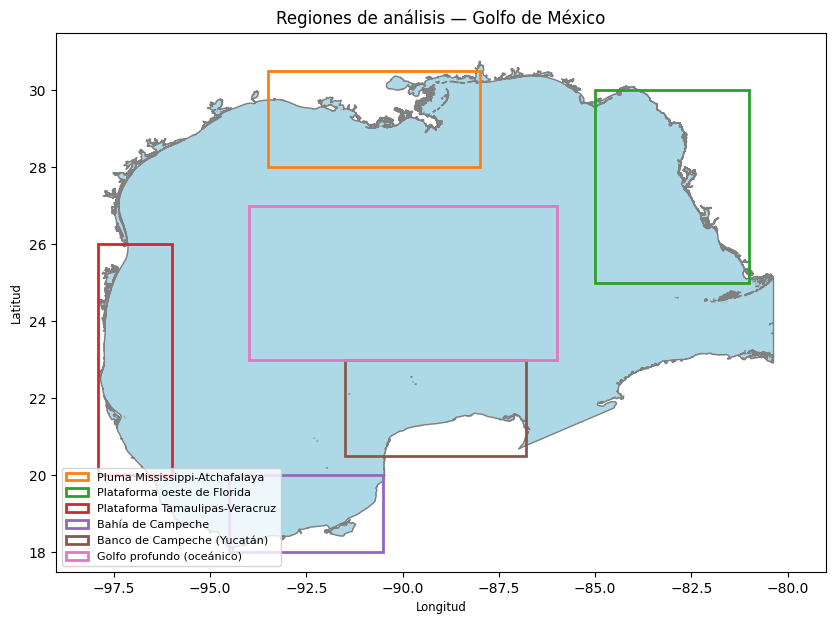

In [ ]:
# ===================== PASO 1.1 — CONFIGURACIÓN (regiones) =====================
import re, time
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import shapely
import earthaccess
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

auth = earthaccess.login(persist=True)

INICIO, FIN = "2003-01-01", "2025-12-31"
BBOX = dict(lon_min=-98.0, lon_max=-80.0, lat_min=18.0, lat_max=31.0)
QUAL_SST_MAX = 1          # 0 = mejor, 1 = buena calidad

BASE = Path("/content/drive/MyDrive/Proyecto_Golfo_Mexico")
DIR_SUB = {"chl": BASE / "subsets" / "clorofila_a",
           "sst": BASE / "subsets" / "sst"}
for d in DIR_SUB.values():
    d.mkdir(parents=True, exist_ok=True)
TMP = Path("/content/tmp_descargas"); TMP.mkdir(exist_ok=True)

# Límite del Golfo (GCOOS), reparado igual que en tu celda 39
url_gom = ("https://services1.arcgis.com/qr14biwnHA6Vis6l/arcgis/rest/services/"
           "GoM_Region_GSHHS/FeatureServer/2/query?where=1%3D1&outFields=*"
           "&returnGeometry=true&outSR=4326&f=geojson")
gdf_golfo = gpd.read_file(url_gom)
geometria_golfo = shapely.make_valid(
    shapely.union_all(gdf_golfo.geometry.make_valid().array))
print("Geometría del Golfo válida:", geometria_golfo.is_valid)

# Regiones de comparación: (lon_min, lon_max, lat_min, lat_max)
# Cada caja se intersecta con el polígono del Golfo, así que la tierra queda fuera.
REGIONES = {
    "Golfo completo":                 None,
    "Pluma Mississippi-Atchafalaya":  (-93.5, -88.0, 28.0, 30.5),
    "Plataforma oeste de Florida":    (-85.0, -81.0, 25.0, 30.0),
    "Plataforma Tamaulipas-Veracruz": (-97.9, -96.0, 20.0, 26.0),
    "Bahía de Campeche":              (-94.5, -90.5, 18.0, 20.0),
    "Banco de Campeche (Yucatán)":    (-91.5, -86.8, 20.5, 23.0),
    "Golfo profundo (oceánico)":      (-94.0, -86.0, 23.0, 27.0),
}

fig, ax = plt.subplots(figsize=(10, 7))
gpd.GeoSeries([geometria_golfo]).plot(ax=ax, color="lightblue", edgecolor="gray")
for i, (nombre, caja) in enumerate(REGIONES.items()):
    if caja is None:
        continue
    x0, x1, y0, y1 = caja
    ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                    lw=2, edgecolor=f"C{i}", label=nombre))
ax.set_xlim(-99, -79); ax.set_ylim(17.5, 31.5)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Regiones de análisis — Golfo de México")
ax.legend(loc="lower left", fontsize=8)
plt.show()

In [ ]:
# ===================== PASO 1.2 — BÚSQUEDA =====================
def nombre_archivo(g):
    for url in g.data_links():
        nombre = url.split("/")[-1]
        if nombre.endswith(".nc"):
            return nombre
    return None

def buscar_mensuales(short_name, version, patron):
    res = earthaccess.search_data(short_name=short_name, version=version,
                                  temporal=(INICIO, FIN), granule_name=patron)
    if len(res) == 0:   # respaldo: buscar sin patrón y filtrar por nombre
        res = earthaccess.search_data(short_name=short_name, version=version,
                                      temporal=(INICIO, FIN))
    esperados = pd.period_range(INICIO[:7], FIN[:7], freq="M")
    por_mes = {}
    for g in res:
        nombre = nombre_archivo(g)
        if not nombre:
            continue
        m = re.search(r"\.(\d{8})_\d{8}\.L3m\.MO\.", nombre)
        if m and "4km" in nombre:
            s = m.group(1)
            mes = pd.Period(f"{s[:4]}-{s[4:6]}", freq="M")
            if mes in esperados:
                por_mes.setdefault(mes, g)       # un granule por mes
    faltan = [str(p) for p in esperados if p not in por_mes]
    print(f"{short_name}: {len(res)} en catálogo → {len(por_mes)} meses únicos")
    print("   Faltantes:", faltan if faltan else "ninguno")
    if por_mes:
        print("   Ejemplo:", nombre_archivo(next(iter(por_mes.values()))))
    return por_mes

granulos = {
    "chl": buscar_mensuales("MODISA_L3m_CHL", "2022.0", "*.MO.CHL.chlor_a.4km*"),
    "sst": buscar_mensuales("MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0",
                            "2019.0", "*.MO.SST.sst.4km*"),
}

MODISA_L3m_CHL: 329 en catálogo → 276 meses únicos
   Faltantes: ninguno
   Ejemplo: AQUA_MODIS.20030101_20030131.L3m.MO.CHL.chlor_a.4km.nc
MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0: 299 en catálogo → 276 meses únicos
   Faltantes: ninguno
   Ejemplo: AQUA_MODIS.20030101_20030131.L3m.MO.SST.sst.4km.nc


In [ ]:
# ===================== PASO 1.3 — FUNCIONES =====================
def ruta_subset(variable, mes):
    return DIR_SUB[variable] / f"{variable}_{mes.strftime('%Y-%m')}.nc"

def recortar_y_guardar(ruta_local, variable, mes):
    with xr.open_dataset(ruta_local) as ds:
        sub = ds.sel(lat=slice(BBOX["lat_max"], BBOX["lat_min"]),
                     lon=slice(BBOX["lon_min"], BBOX["lon_max"]))
        if variable == "chl":
            da = sub["chlor_a"].load()
            da = da.where((da >= 0.001) & (da <= 100))
        else:
            da = sub["sst"].load()
            if "qual_sst" in sub:
                da = da.where(sub["qual_sst"].load() <= QUAL_SST_MAX)
            da = da.where((da >= -2) & (da <= 40))
    # DataArray "limpio", sin la codificación del archivo original
    out = xr.DataArray(
        da.values[np.newaxis].astype("float32"),
        coords={"time": [mes.to_timestamp()],
                "lat": da.lat.values, "lon": da.lon.values},
        dims=("time", "lat", "lon"), name=variable,
        attrs={"units": "mg m-3" if variable == "chl" else "degC"})
    destino = ruta_subset(variable, mes)
    tmp = destino.parent / (destino.name + ".tmp")
    out.to_netcdf(tmp, encoding={variable: {"zlib": True, "complevel": 4}})
    tmp.replace(destino)

def procesar_variable(variable, por_mes, lote=12):
    pendientes = [(m, g) for m, g in sorted(por_mes.items())
                  if not ruta_subset(variable, m).exists()]
    print(f"[{variable}] listos: {len(por_mes) - len(pendientes)} | pendientes: {len(pendientes)}")
    errores, t0 = [], time.time()
    for i in range(0, len(pendientes), lote):
        bloque = pendientes[i:i + lote]
        try:
            earthaccess.download([g for _, g in bloque], local_path=str(TMP), threads=6)
        except Exception as e:
            errores += [(str(m), "descarga: " + repr(e)) for m, _ in bloque]
            continue
        for mes, g in bloque:
            try:
                recortar_y_guardar(TMP / nombre_archivo(g), variable, mes)
            except Exception as e:
                errores.append((str(mes), repr(e)))
        for p in TMP.iterdir():          # borrar los archivos globales
            if p.is_file():
                p.unlink()
        print(f"   {min(i + lote, len(pendientes))}/{len(pendientes)} "
              f"(hasta {bloque[-1][0]}) — {(time.time() - t0) / 60:.1f} min")
    print(f"[{variable}] errores: {len(errores)}")
    for e in errores[:10]:
        print("   ", e)
    return errores

print("Funciones listas.")

Funciones listas.


In [ ]:
# ===================== PASO 1.4 — EJECUCIÓN =====================
errores_chl = procesar_variable("chl", granulos["chl"])
errores_sst = procesar_variable("sst", granulos["sst"])

[chl] listos: 0 | pendientes: 276


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

   12/276 (hasta 2003-12) — 0.4 min


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

... (175 outputs left out)

QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

   276/276 (hasta 2025-12) — 2.3 min
[sst] errores: 0


In [ ]:
# ===================== PASO 1.5 — SERIES REGIONALES =====================
def cargar_cubo(variable):
    partes = []
    for f in sorted(DIR_SUB[variable].glob(f"{variable}_*.nc")):
        with xr.open_dataarray(f) as a:
            partes.append(a.load())
    cubo = xr.concat(partes, dim="time").sortby("time")
    cubo.to_netcdf(BASE / f"cubo_{variable}_2003_2025.nc",
                   encoding={variable: {"zlib": True, "complevel": 4}})
    return cubo

def mascaras_regiones(da):
    lon2d, lat2d = np.meshgrid(da.lon.values, da.lat.values)
    oceano = shapely.contains_xy(geometria_golfo, lon2d, lat2d)
    mascaras = {}
    for nombre, caja in REGIONES.items():
        m = oceano.copy()
        if caja is not None:
            x0, x1, y0, y1 = caja
            m &= (lon2d >= x0) & (lon2d <= x1) & (lat2d >= y0) & (lat2d <= y1)
        mascaras[nombre] = xr.DataArray(m, coords={"lat": da.lat, "lon": da.lon},
                                        dims=("lat", "lon"))
    return mascaras

def series_regionales(cubo, variable, cobertura_min=25):
    pesos = np.cos(np.deg2rad(cubo.lat))          # corrige el área del píxel
    tablas = []
    for nombre, m in mascaras_regiones(cubo).items():
        datos = cubo.where(m)
        transf = np.log10(datos) if variable == "chl" else datos
        media = transf.weighted(pesos).mean(("lat", "lon"))
        n_val = datos.notnull().sum(("lat", "lon"))
        df = pd.DataFrame({
            "fecha": pd.to_datetime(cubo.time.values),
            "variable": variable,
            "region": nombre,
            # chl: media geométrica (10^media de log10); sst: media aritmética
            "media": 10 ** media.values if variable == "chl" else media.values,
            "mediana": datos.median(("lat", "lon")).values,
            "cobertura_pct": 100 * n_val.values / int(m.sum()),
            "pixeles_region": int(m.sum()),
        })
        df.loc[df.cobertura_pct < cobertura_min, ["media", "mediana"]] = np.nan
        tablas.append(df)
    return pd.concat(tablas, ignore_index=True)

cubos = {v: cargar_cubo(v) for v in ["chl", "sst"]}
for v, c in cubos.items():
    print(v, dict(c.sizes))

series = pd.concat([series_regionales(cubos[v], v) for v in cubos], ignore_index=True)
series.to_csv(BASE / "series_regionales_mensuales.csv", index=False)

resumen = (series.groupby(["variable", "region"])
           .agg(meses_validos=("media", "count"),
                media=("media", "mean"),
                minimo=("media", "min"),
                maximo=("media", "max"),
                cobertura_prom=("cobertura_pct", "mean"),
                pixeles=("pixeles_region", "first"))
           .round(3))
display(resumen)

/tmp/ipykernel_8286/112110945.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'lat' ('lat',) The recommendation is to set join explicitly for this case.
  cubo = xr.concat(partes, dim="time").sortby("time")
/tmp/ipykernel_8286/112110945.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'lon' ('lon',) The recommendation is to set join explicitly for this case.
  cubo = xr.concat(partes, dim="time").sortby("time")


chl {'time': 276, 'lat': 312, 'lon': 432}
sst {'time': 276, 'lat': 584, 'lon': 576}


meses_validos      media     minimo  \
variable region                                                                
chl      Bahía de Campeche                         276   0.610000   0.259000   
         Banco de Campeche (Yucatán)               276   0.331000   0.181000   
         Golfo completo                            276   0.235000   0.134000   
         Golfo profundo (oceánico)                 276   0.115000   0.057000   
         Plataforma Tamaulipas-Veracruz            276   0.243000   0.089000   
         Plataforma oeste de Florida               276   0.458000   0.231000   
         Pluma Mississippi-Atchafalaya             276   1.650000   0.855000   
sst      Bahía de Campeche                         276  27.764000  23.535000   
         Banco de Campeche (Yucatán)               276  27.098000  23.122999   
         Golfo completo                            276  26.733000  21.507999   
         Golfo profundo (oceánico)                 276  27.174999  22.469000   
         Plataforma Tamaulipas-Veracruz            276  26.615000  20.771000   
         Plataforma oeste de Florida               276  25.766001  17.924000   
         Pluma Mississippi-Atchafalaya             276  24.959000  16.104000   

                                            maximo  cobertura_prom  pixeles  
variable region                                                              
chl      Bahía de Campeche                1.628000          98.887     3156  
         Banco de Campeche (Yucatán)      0.702000          99.760     4898  
         Golfo completo                   0.467000          99.404    82838  
         Golfo profundo (oceánico)        0.287000          99.846    18432  
         Plataforma Tamaulipas-Veracruz   0.603000          98.275     5300  
         Plataforma oeste de Florida      0.926000          99.461     7514  
         Pluma Mississippi-Atchafalaya    4.654000          98.449     5470  
sst      Bahía de Campeche               31.431000          37.535     8408  
         Banco de Campeche (Yucatán)     31.424999          37.404    13094  
         Golfo completo                  31.437000          39.987   207056  
         Golfo profundo (oceánico)       31.645000          39.130    47104  
         Plataforma Tamaulipas-Veracruz  31.443001          37.461    14134  
         Plataforma oeste de Florida     32.073002          42.470    17677  
         Pluma Mississippi-Atchafalaya   32.571999          44.890    12165

In [56]:
# ===================== PASO 1.6 — CORREGIR REJILLA SST =====================
import collections

# Diagnóstico: ¿cuántas rejillas distintas hay entre los archivos SST?
rejillas = collections.Counter()
for f in sorted(DIR_SUB["sst"].glob("sst_*.nc")):
    with xr.open_dataarray(f) as a:
        rejillas[(a.sizes["lat"], a.sizes["lon"],
                  round(float(a.lat[0]), 5), round(float(a.lon[0]), 5))] += 1
print("Rejillas distintas en SST:", len(rejillas))
for k, n in rejillas.most_common(5):
    print("   (nlat, nlon, lat0, lon0) =", k, "→", n, "archivos")
print("Cubo chl:", dict(cubos["chl"].sizes), "| cubo sst actual:", dict(cubos["sst"].sizes))

# Corrección: cada mes de SST va a la rejilla exacta de la clorofila
ref = cubos["chl"]
partes = []
for f in sorted(DIR_SUB["sst"].glob("sst_*.nc")):
    with xr.open_dataarray(f) as a:
        a = a.load().sortby("lat", ascending=False).sortby("lon")
        a = a.reindex(lat=ref.lat, lon=ref.lon, method="nearest", tolerance=0.02)
        partes.append(a)
cubos["sst"] = xr.concat(partes, dim="time").sortby("time")
cubos["sst"].to_netcdf(BASE / "cubo_sst_2003_2025.nc",
                       encoding={"sst": {"zlib": True, "complevel": 4}})
print("Cubo sst corregido:", dict(cubos["sst"].sizes))

# Recalcular las series y el resumen
series = pd.concat([series_regionales(cubos[v], v) for v in ["chl", "sst"]],
                   ignore_index=True)
series.to_csv(BASE / "series_regionales_mensuales.csv", index=False)
resumen = (series.groupby(["variable", "region"])
           .agg(meses_validos=("media", "count"), media=("media", "mean"),
                minimo=("media", "min"), maximo=("media", "max"),
                cobertura_prom=("cobertura_pct", "mean"),
                pixeles=("pixeles_region", "first"))
           .round(3))
display(resumen)

Rejillas distintas en SST: 2
   (nlat, nlon, lat0, lon0) = (312, 432, 30.97917, -97.97916) → 186 archivos
   (nlat, nlon, lat0, lon0) = (312, 432, 30.97916, -97.97916) → 90 archivos
Cubo chl: {'time': 276, 'lat': 312, 'lon': 432} | cubo sst actual: {'time': 276, 'lat': 584, 'lon': 576}
Cubo sst corregido: {'time': 276, 'lat': 312, 'lon': 432}


meses_validos      media     minimo  \
variable region                                                                
chl      Bahía de Campeche                         276   0.610000   0.259000   
         Banco de Campeche (Yucatán)               276   0.331000   0.181000   
         Golfo completo                            276   0.235000   0.134000   
         Golfo profundo (oceánico)                 276   0.115000   0.057000   
         Plataforma Tamaulipas-Veracruz            276   0.243000   0.089000   
         Plataforma oeste de Florida               276   0.458000   0.231000   
         Pluma Mississippi-Atchafalaya             276   1.650000   0.855000   
sst      Bahía de Campeche                         276  27.764000  23.535000   
         Banco de Campeche (Yucatán)               276  27.098000  23.122000   
         Golfo completo                            276  26.733000  21.507999   
         Golfo profundo (oceánico)                 276  27.174999  22.469000   
         Plataforma Tamaulipas-Veracruz            276  26.615000  20.771000   
         Plataforma oeste de Florida               276  25.766001  17.924000   
         Pluma Mississippi-Atchafalaya             276  24.959000  16.104000   

                                            maximo  cobertura_prom  pixeles  
variable region                                                              
chl      Bahía de Campeche                1.628000          98.887     3156  
         Banco de Campeche (Yucatán)      0.702000          99.760     4898  
         Golfo completo                   0.467000          99.404    82838  
         Golfo profundo (oceánico)        0.287000          99.846    18432  
         Plataforma Tamaulipas-Veracruz   0.603000          98.275     5300  
         Plataforma oeste de Florida      0.926000          99.461     7514  
         Pluma Mississippi-Atchafalaya    4.654000          98.449     5470  
sst      Bahía de Campeche               31.431000          99.999     3156  
         Banco de Campeche (Yucatán)     31.424999          99.995     4898  
         Golfo completo                  31.437000          99.948    82838  
         Golfo profundo (oceánico)       31.645000          99.999    18432  
         Plataforma Tamaulipas-Veracruz  31.443001          99.901     5300  
         Plataforma oeste de Florida     32.073002          99.914     7514  
         Pluma Mississippi-Atchafalaya   32.571999          99.820     5470

In [57]:
# ===================== PASO 2.1 — CLIMATOLOGÍA Y ANOMALÍAS =====================
from scipy import stats

ORDEN = ["Golfo completo", "Pluma Mississippi-Atchafalaya", "Plataforma oeste de Florida",
         "Plataforma Tamaulipas-Veracruz", "Bahía de Campeche",
         "Banco de Campeche (Yucatán)", "Golfo profundo (oceánico)"]

series = pd.read_csv(BASE / "series_regionales_mensuales.csv", parse_dates=["fecha"])
df = series[["fecha", "variable", "region", "media"]].copy()

# Clorofila en log10 (distribución sesgada); SST en °C
df["y"] = np.where(df.variable == "chl", np.log10(df.media), df.media)
df["mes"] = df.fecha.dt.month

clim = (df.groupby(["variable", "region", "mes"])["y"].mean()
          .rename("clim").reset_index())
df = df.merge(clim, on=["variable", "region", "mes"]).sort_values(["variable", "region", "fecha"])
df["anomalia"] = df.y - df.clim                       # chl: log10 ; sst: °C
df["anomalia_pct"] = np.where(df.variable == "chl",
                              (10 ** df.anomalia - 1) * 100, np.nan)  # chl en %
df.to_csv(BASE / "series_anomalias.csv", index=False)
print("Guardado:", BASE / "series_anomalias.csv", "| filas:", len(df))

Guardado: /content/drive/MyDrive/Proyecto_Golfo_Mexico/series_anomalias.csv | filas: 3864


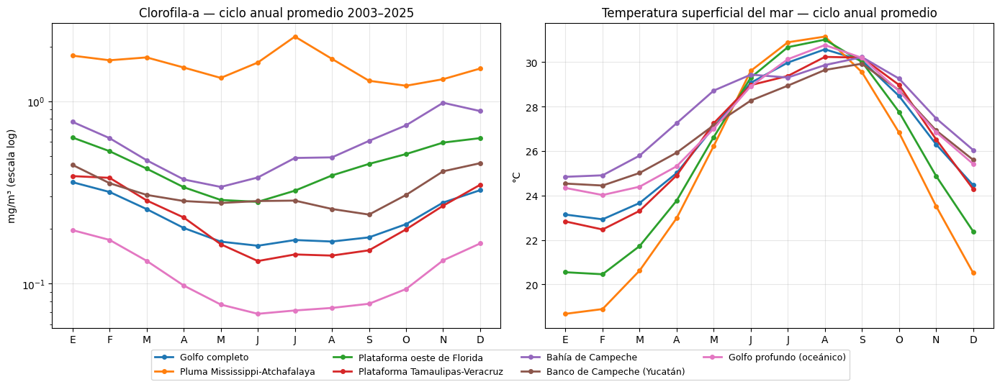

In [58]:
# ===================== PASO 2.2 — CICLO ESTACIONAL =====================
MESES = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, var in zip(axes, ["chl", "sst"]):
    for i, reg in enumerate(ORDEN):
        d = clim[(clim.variable == var) & (clim.region == reg)].sort_values("mes")
        y = 10 ** d.clim if var == "chl" else d.clim
        ax.plot(d.mes, y, lw=2, marker="o", ms=4, color=f"C{i}", label=reg)
    ax.set_xticks(range(1, 13), MESES)
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].set_title("Clorofila-a — ciclo anual promedio 2003–2025")
axes[0].set_ylabel("mg/m³ (escala log)")
axes[1].set_title("Temperatura superficial del mar — ciclo anual promedio")
axes[1].set_ylabel("°C")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

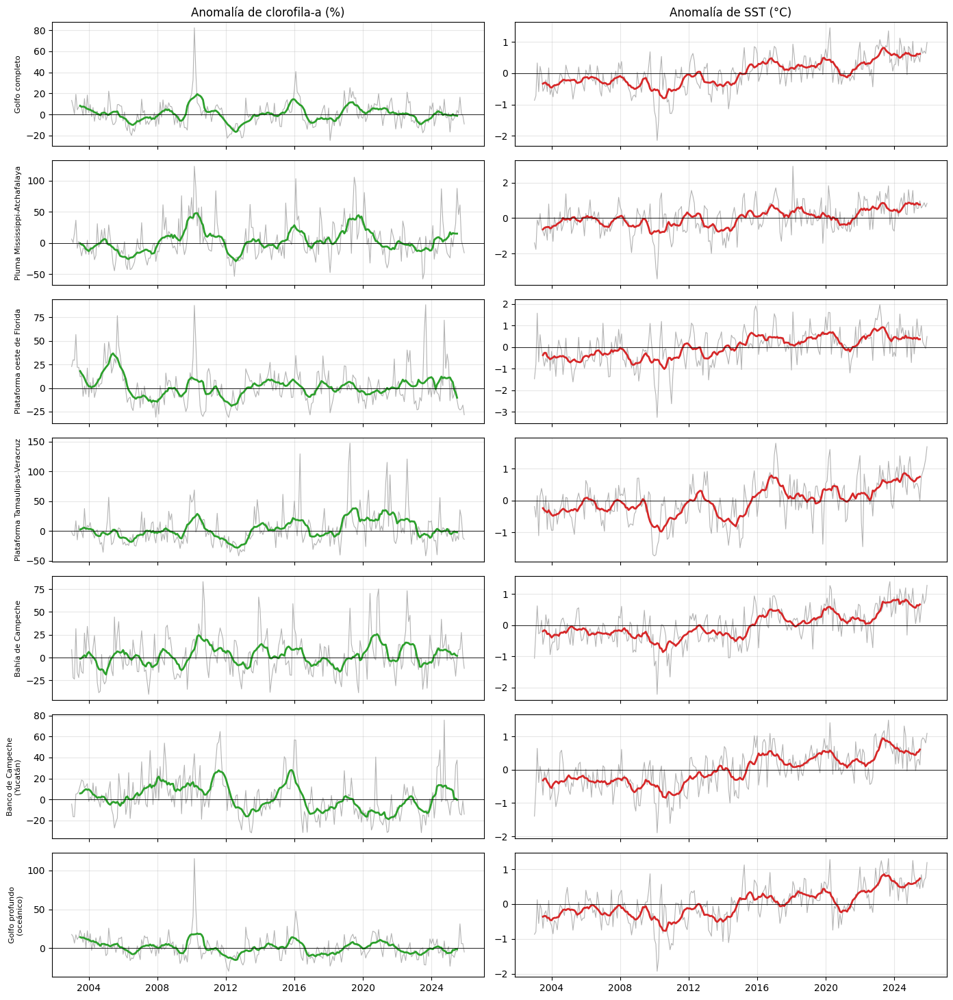

In [59]:
# ===================== PASO 2.3 — ANOMALÍAS EN EL TIEMPO =====================
fig, axes = plt.subplots(len(ORDEN), 2, figsize=(14, 2.1 * len(ORDEN)), sharex=True)
for r, reg in enumerate(ORDEN):
    for c, var in enumerate(["chl", "sst"]):
        ax = axes[r, c]
        d = df[(df.variable == var) & (df.region == reg)].set_index("fecha")
        y = d.anomalia_pct if var == "chl" else d.anomalia
        ax.plot(y.index, y, color="0.7", lw=0.8)
        ax.plot(y.index, y.rolling(12, center=True).mean(),
                color="tab:green" if var == "chl" else "tab:red", lw=2)
        ax.axhline(0, color="k", lw=0.6)
        ax.grid(alpha=0.3)
        if c == 0:
            ax.set_ylabel(reg.replace(" (", "\n("), fontsize=8)
axes[0, 0].set_title("Anomalía de clorofila-a (%)")
axes[0, 1].set_title("Anomalía de SST (°C)")
plt.tight_layout(); plt.show()

In [60]:
# ===================== PASO 2.4 — DIAGNÓSTICOS =====================
filas = []
for (var, reg), d in df.groupby(["variable", "region"]):
    a = d.sort_values("fecha").anomalia.dropna()
    r1 = a.autocorr(1)
    filas.append({
        "variable": var, "region": reg,
        "asimetria_original": stats.skew(d.media.dropna()),
        "asimetria_analizada": stats.skew(d.y.dropna()),   # chl: log10
        "autocorr_lag1": r1,
        "n": len(a),
        "n_efectivo_aprox": len(a) * (1 - r1) / (1 + r1),
    })
diag = pd.DataFrame(filas).set_index(["variable", "region"]).round(2)
display(diag)

asimetria_original  \
variable region                                               
chl      Bahía de Campeche                             1.09   
         Banco de Campeche (Yucatán)                   0.73   
         Golfo completo                                0.81   
         Golfo profundo (oceánico)                     0.92   
         Plataforma Tamaulipas-Veracruz                0.89   
         Plataforma oeste de Florida                   0.66   
         Pluma Mississippi-Atchafalaya                 1.79   
sst      Bahía de Campeche                            -0.31   
         Banco de Campeche (Yucatán)                  -0.02   
         Golfo completo                               -0.04   
         Golfo profundo (oceánico)                     0.08   
         Plataforma Tamaulipas-Veracruz               -0.19   
         Plataforma oeste de Florida                  -0.08   
         Pluma Mississippi-Atchafalaya                -0.04   

                                         asimetria_analizada  autocorr_lag1  \
variable region                                                               
chl      Bahía de Campeche                              0.19           0.49   
         Banco de Campeche (Yucatán)                    0.17           0.57   
         Golfo completo                                 0.41           0.61   
         Golfo profundo (oceánico)                      0.40           0.56   
         Plataforma Tamaulipas-Veracruz                 0.16           0.51   
         Plataforma oeste de Florida                    0.14           0.64   
         Pluma Mississippi-Atchafalaya                  0.73           0.54   
sst      Bahía de Campeche                             -0.31           0.63   
         Banco de Campeche (Yucatán)                   -0.02           0.63   
         Golfo completo                                -0.04           0.68   
         Golfo profundo (oceánico)                      0.08           0.67   
         Plataforma Tamaulipas-Veracruz                -0.19           0.64   
         Plataforma oeste de Florida                   -0.08           0.51   
         Pluma Mississippi-Atchafalaya                 -0.04           0.47   

                                           n  n_efectivo_aprox  
variable region                                                 
chl      Bahía de Campeche               276             95.20  
         Banco de Campeche (Yucatán)     276             74.86  
         Golfo completo                  276             65.89  
         Golfo profundo (oceánico)       276             78.90  
         Plataforma Tamaulipas-Veracruz  276             89.87  
         Plataforma oeste de Florida     276             60.25  
         Pluma Mississippi-Atchafalaya   276             82.50  
sst      Bahía de Campeche               276             63.64  
         Banco de Campeche (Yucatán)     276             61.75  
         Golfo completo                  276             53.55  
         Golfo profundo (oceánico)       276             53.93  
         Plataforma Tamaulipas-Veracruz  276             59.56  
         Plataforma oeste de Florida     276             88.95  
         Pluma Mississippi-Atchafalaya   276             98.30

In [61]:
# ===================== PASO 3.1 — FUNCIONES DE TENDENCIA =====================
import pymannkendall as mk
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy import stats

def sen_con_ic(t, y, var_s, alfa=0.05):
    """Pendiente de Sen + IC (Gilbert 1987) usando la varianza de S corregida."""
    i, j = np.triu_indices(len(y), k=1)
    pendientes = np.sort((y[j] - y[i]) / (t[j] - t[i]))
    N = len(pendientes)
    C = stats.norm.ppf(1 - alfa / 2) * np.sqrt(var_s)
    lo = int(np.clip(np.floor((N - C) / 2), 0, N - 1))
    hi = int(np.clip(np.ceil((N + C) / 2), 0, N - 1))
    return np.median(pendientes), pendientes[lo], pendientes[hi]

def analizar_tendencia(d, var):
    d = d.sort_values("fecha").dropna(subset=["anomalia"])
    t = ((d.fecha - d.fecha.iloc[0]).dt.days / 365.25).values   # años
    y = d.anomalia.values           # chl: log10 ; sst: °C
    T = t[-1]                       # duración del periodo (años)

    mk_cl = mk.original_test(y)
    mk_hr = mk.hamed_rao_modification_test(y)
    mk_se = mk.seasonal_test(d.y.values, period=12)

    sen, sen_lo, sen_hi = sen_con_ic(t, y, mk_hr.var_s)           # por año
    ols = sm.OLS(y, sm.add_constant(t)).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    b, (b_lo, b_hi), p_ols = ols.params[1], ols.conf_int()[1], ols.pvalues[1]

    # Unidades finales: por década
    if var == "chl":
        a_pct = lambda x: (10 ** x - 1) * 100       # log10 → %
        nivel = 10 ** d.y.mean()                    # media geométrica (mg/m³)
        fila = {
            "Sen (%/década)": a_pct(sen * 10),
            "IC95 inf": a_pct(sen_lo * 10), "IC95 sup": a_pct(sen_hi * 10),
            "Sen (mg/m³/década)": nivel * (10 ** (sen * 10) - 1),
            "Cambio total (%)": a_pct(sen * T),
            "OLS (%/década)": a_pct(b * 10),
            "OLS IC95 inf": a_pct(b_lo * 10), "OLS IC95 sup": a_pct(b_hi * 10),
        }
    else:
        fila = {
            "Sen (°C/década)": sen * 10,
            "IC95 inf": sen_lo * 10, "IC95 sup": sen_hi * 10,
            "Cambio total (°C)": sen * T,
            "OLS (°C/década)": b * 10,
            "OLS IC95 inf": b_lo * 10, "OLS IC95 sup": b_hi * 10,
        }
    fila.update({
        "tau Kendall": mk_hr.Tau,
        "p MK clásico": mk_cl.p,
        "p MK Hamed-Rao": mk_hr.p,
        "p OLS-HAC": p_ols,
        "p Seasonal Kendall": mk_se.p,
        "años": T,
    })
    return fila

print("Funciones listas.")

Funciones listas.


In [62]:
# ===================== PASO 3.2 — TABLA DE TENDENCIAS =====================
df = pd.read_csv(BASE / "series_anomalias.csv", parse_dates=["fecha"])

filas = []
for var in ["chl", "sst"]:
    for reg in ORDEN:
        d = df[(df.variable == var) & (df.region == reg)]
        f = analizar_tendencia(d, var)
        f.update({"variable": var, "region": reg})
        filas.append(f)
tend = pd.DataFrame(filas)

# Corrección por pruebas múltiples (14 pruebas)
tend["q (BH-FDR)"] = multipletests(tend["p MK Hamed-Rao"], method="fdr_bh")[1]

def clasificar(r):
    col = "Sen (%/década)" if r.variable == "chl" else "Sen (°C/década)"
    sentido = "Aumento" if r[col] > 0 else "Disminución"
    if r["p MK Hamed-Rao"] < 0.05:
        return f"{sentido} significativo"
    if r["p MK Hamed-Rao"] < 0.10:
        return f"{sentido} marginal (p<0.10)"
    return "Sin tendencia detectada"
tend["Resultado"] = tend.apply(clasificar, axis=1)
tend.to_csv(BASE / "tabla_tendencias.csv", index=False)

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
for var, titulo in [("chl", "CLOROFILA-a"), ("sst", "TEMPERATURA SUPERFICIAL DEL MAR")]:
    print("\n" + "=" * 70 + f"\n{titulo}\n" + "=" * 70)
    display(tend[tend.variable == var].dropna(axis=1, how="all")
            .drop(columns="variable").set_index("region"))


CLOROFILA-a


,Sen (%/década),IC95 inf,IC95 sup,Sen (mg/m³/década),Cambio total (%),OLS (%/década),OLS IC95 inf,OLS IC95 sup,tau Kendall,p MK clásico,p MK Hamed-Rao,p OLS-HAC,p Seasonal Kendall,años,q (BH-FDR),Resultado
region,,,,,,,,,,,,,,,,
Golfo completo,-0.2781,-2.568,1.9,-0.0006249,-0.6361,-0.3198,-3.168,2.613,-0.01196,0.7675,0.8085,0.8286,0.9696,22.92,0.8085,Sin tendencia detectada
Pluma Mississippi-Atchafalaya,5.261,0.4149,10.47,0.08231,12.47,5.136,-2.956,13.9,0.09249,0.02204,0.03399,0.2203,0.03096,22.92,0.05288,Aumento significativo
Plataforma oeste de Florida,-2.819,-7.122,1.753,-0.01221,-6.343,-2.558,-8.769,4.075,-0.0712,0.078,0.2175,0.4406,0.2254,22.92,0.2512,Sin tendencia detectada
Plataforma Tamaulipas-Veracruz,5.378,-0.8156,12.34,0.0118,12.75,6.278,-0.1736,13.15,0.1102,0.006369,0.09048,0.0567,0.03882,22.92,0.1152,Aumento marginal (p<0.10)
Bahía de Campeche,2.632,-1.641,6.829,0.01486,6.135,2.913,-1.646,7.684,0.05444,0.1778,0.2332,0.2142,0.1453,22.92,0.2512,Sin tendencia detectada
Banco de Campeche (Yucatán),-6.739,-11.68,-1.224,-0.0215,-14.78,-6.128,-11.05,-0.938,-0.1836,5.5e-06,0.01869,0.02127,7.104e-06,22.92,0.03271,Disminución significativo
Golfo profundo (oceánico),-3,-5.968,0.2041,-0.003175,-6.743,-2.957,-6.109,0.3011,-0.1106,0.00617,0.06591,0.07483,0.02651,22.92,0.09228,Disminución marginal (p<0.10)



TEMPERATURA SUPERFICIAL DEL MAR


,IC95 inf,IC95 sup,OLS IC95 inf,OLS IC95 sup,tau Kendall,p MK clásico,p MK Hamed-Rao,p OLS-HAC,p Seasonal Kendall,años,Sen (°C/década),Cambio total (°C),OLS (°C/década),q (BH-FDR),Resultado
region,,,,,,,,,,,,,,,
Golfo completo,0.3463,0.5574,0.3537,0.58,0.4172,0,2.578e-13,6.263e-16,0,22.92,0.4528,1.038,0.4668,1.805e-12,Aumento significativo
Pluma Mississippi-Atchafalaya,0.297,0.6146,0.2866,0.6401,0.2469,9.835e-10,8.348e-08,2.784e-07,1.118e-09,22.92,0.4545,1.042,0.4634,1.67e-07,Aumento significativo
Plataforma oeste de Florida,0.4022,0.6961,0.4095,0.6925,0.3276,4.441e-16,2.728e-11,2.321e-14,7.994e-15,22.92,0.5501,1.261,0.551,1.273e-10,Aumento significativo
Plataforma Tamaulipas-Veracruz,0.3141,0.5624,0.3018,0.5958,0.3211,1.776e-15,1.147e-10,2.155e-09,2.665e-15,22.92,0.4368,1.001,0.4488,4.015e-10,Aumento significativo
Bahía de Campeche,0.3127,0.6048,0.3169,0.6091,0.3796,0,3.086e-08,5.241e-10,0,22.92,0.4597,1.053,0.463,7.201e-08,Aumento significativo
Banco de Campeche (Yucatán),0.4284,0.6361,0.4115,0.6628,0.4172,0,0,5.373e-17,0,22.92,0.5304,1.215,0.5371,0,Aumento significativo
Golfo profundo (oceánico),0.3105,0.5762,0.3205,0.5776,0.4053,0,9.297e-09,7.53e-12,0,22.92,0.4435,1.016,0.449,2.603e-08,Aumento significativo


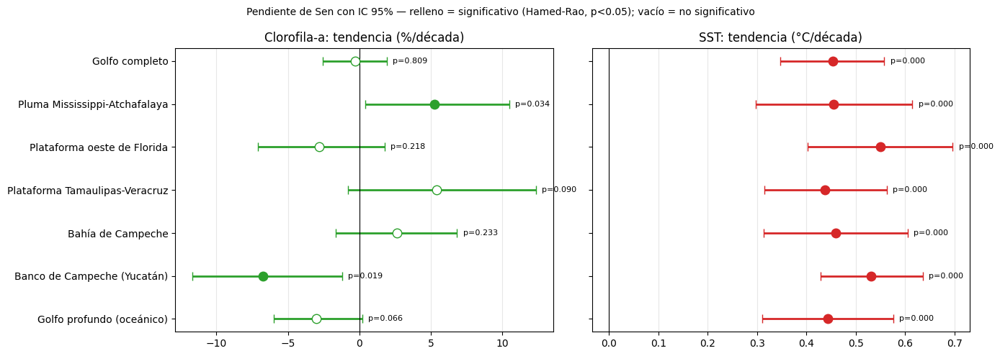

In [63]:
# ===================== PASO 3.3 — GRÁFICA DE TENDENCIAS =====================
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
config = [("chl", "Sen (%/década)", "Clorofila-a: tendencia (%/década)", "tab:green"),
          ("sst", "Sen (°C/década)", "SST: tendencia (°C/década)", "tab:red")]
for ax, (var, col, titulo, color) in zip(axes, config):
    d = tend[tend.variable == var].set_index("region").loc[ORDEN[::-1]]
    ypos = np.arange(len(d))
    for k, (reg, r) in enumerate(d.iterrows()):
        sig = r["p MK Hamed-Rao"] < 0.05
        ax.errorbar(r[col], k, xerr=[[r[col] - r["IC95 inf"]], [r["IC95 sup"] - r[col]]],
                    fmt="o", ms=9, capsize=4, lw=2, color=color,
                    mfc=color if sig else "white")
        ax.annotate(f"p={r['p MK Hamed-Rao']:.3f}", (r["IC95 sup"], k),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(ypos, d.index)
    ax.set_title(titulo); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Pendiente de Sen con IC 95% — relleno = significativo (Hamed-Rao, p<0.05); "
             "vacío = no significativo", fontsize=10)
plt.tight_layout(); plt.show()

In [64]:
# ===================== PASO 4.1 — ANOMALÍAS POR CELDA =====================
FACTOR = 6                                    # 6 × 0.0417° ≈ 0.25°
oceano = mascaras_regiones(cubos["chl"])["Golfo completo"]

def anomalias_rejilla(var):
    c = cubos[var].where(oceano)
    if var == "chl":
        c = np.log10(c)
    n = c.notnull().coarsen(lat=FACTOR, lon=FACTOR, boundary="trim").sum()
    g = c.coarsen(lat=FACTOR, lon=FACTOR, boundary="trim").mean()
    g = g.where(n >= FACTOR * FACTOR / 2)     # al menos 50% de subpíxeles válidos
    clim = g.groupby("time.month").mean("time")
    return (g.groupby("time.month") - clim).drop_vars("month")

anom_grid = {v: anomalias_rejilla(v) for v in ["chl", "sst"]}
for v, a in anom_grid.items():
    print(v, dict(a.sizes), "| celdas con datos:", int(a.notnull().any("time").sum()))

chl {'time': 276, 'lat': 52, 'lon': 72} | celdas con datos: 2313
sst {'time': 276, 'lat': 52, 'lon': 72} | celdas con datos: 2315


In [65]:
# ===================== PASO 4.2 — TENDENCIAS POR CELDA =====================
import warnings
warnings.filterwarnings("ignore")

def tendencias_pixel(anom, var):
    Y = anom.values
    nt, ny, nx = Y.shape
    pend = np.full((ny, nx), np.nan)
    pval = np.full((ny, nx), np.nan)
    t0 = time.time()
    for i in range(ny):
        for j in range(nx):
            y = Y[:, i, j]
            ok = np.isfinite(y)
            if ok.sum() < 0.8 * nt:
                continue
            r = mk.hamed_rao_modification_test(y[ok])
            pend[i, j] = r.slope * 120            # pasos mensuales → por década
            pval[i, j] = r.p
        if i % 10 == 0:
            print(f"   {var}: fila {i}/{ny} — {(time.time() - t0) / 60:.1f} min")
    if var == "chl":
        pend = (10 ** pend - 1) * 100             # log10 → %/década
    sig = np.zeros_like(pval, dtype=bool)
    f = np.isfinite(pval)
    sig[f] = multipletests(pval[f], method="fdr_bh", alpha=0.05)[0]
    return xr.Dataset({"pendiente": (("lat", "lon"), pend),
                       "p": (("lat", "lon"), pval),
                       "sig_fdr": (("lat", "lon"), sig)},
                      coords={"lat": anom.lat, "lon": anom.lon})

mapas = {v: tendencias_pixel(anom_grid[v], v) for v in ["chl", "sst"]}
for v, ds in mapas.items():
    ds.to_netcdf(BASE / f"mapa_tendencias_{v}.nc")
    n = int(np.isfinite(ds.p).sum())
    print(f"{v}: {n} celdas | significativas (FDR): {int(ds.sig_fdr.sum())} "
          f"({100 * int(ds.sig_fdr.sum()) / n:.1f}%)")

   chl: fila 0/52 — 0.0 min
   chl: fila 10/52 — 0.1 min
   chl: fila 20/52 — 0.2 min
   chl: fila 30/52 — 0.4 min
   chl: fila 40/52 — 0.5 min
   chl: fila 50/52 — 0.6 min
   sst: fila 0/52 — 0.0 min
   sst: fila 10/52 — 0.1 min
   sst: fila 20/52 — 0.2 min
   sst: fila 30/52 — 0.3 min
   sst: fila 40/52 — 0.4 min
   sst: fila 50/52 — 0.5 min
chl: 2280 celdas | significativas (FDR): 321 (14.1%)
sst: 2310 celdas | significativas (FDR): 2309 (100.0%)


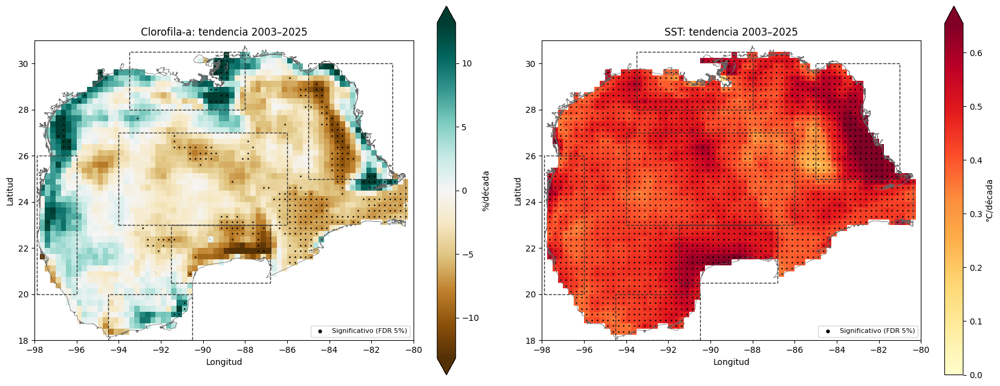

In [66]:
# ===================== PASO 4.3 — MAPAS DE TENDENCIA =====================
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
config = [("chl", "Clorofila-a: tendencia 2003–2025", "%/década"),
          ("sst", "SST: tendencia 2003–2025", "°C/década")]
for ax, (var, titulo, unidad) in zip(axes, config):
    ds = mapas[var]
    vals = ds.pendiente.values
    if np.nanmin(vals) > 0:                       # todo positivo → escala secuencial
        kw = dict(cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(vals, 98))
    else:                                         # divergente centrada en cero
        lim = np.nanpercentile(np.abs(vals), 98)
        kw = dict(cmap="BrBG" if var == "chl" else "RdBu_r", vmin=-lim, vmax=lim)
    ds.pendiente.plot(ax=ax, cbar_kwargs={"label": unidad}, **kw)
    lon2, lat2 = np.meshgrid(ds.lon, ds.lat)
    s = ds.sig_fdr.values
    ax.scatter(lon2[s], lat2[s], s=3, c="k", marker=".", label="Significativo (FDR 5%)")
    gdf_golfo.boundary.plot(ax=ax, color="0.4", lw=0.5)
    for nombre, caja in REGIONES.items():
        if caja:
            x0, x1, y0, y1 = caja
            ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                            fill=False, lw=1, ls="--", edgecolor="0.2"))
    ax.set_xlim(-98, -80); ax.set_ylim(18, 31)
    ax.set_title(titulo); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
    ax.legend(loc="lower right", fontsize=8, markerscale=4)
plt.tight_layout(); plt.show()

In [67]:
# ===================== PASO 4.4 — RESUMEN ESPACIAL POR REGIÓN =====================
filas = []
for var, ds in mapas.items():
    lon2, lat2 = np.meshgrid(ds.lon, ds.lat)
    pend, sig = ds.pendiente.values, ds.sig_fdr.values
    for nombre in ORDEN:
        m = np.isfinite(pend)
        caja = REGIONES[nombre]
        if caja:
            x0, x1, y0, y1 = caja
            m &= (lon2 >= x0) & (lon2 <= x1) & (lat2 >= y0) & (lat2 <= y1)
        n = m.sum()
        filas.append({
            "variable": var, "region": nombre, "celdas": int(n),
            "pendiente_mediana": np.nanmedian(pend[m]),
            "% celdas con aumento significativo": 100 * (sig & (pend > 0) & m).sum() / n,
            "% celdas con disminución significativa": 100 * (sig & (pend < 0) & m).sum() / n,
        })
resumen_espacial = pd.DataFrame(filas).set_index(["variable", "region"]).round(2)
resumen_espacial.to_csv(BASE / "resumen_espacial_tendencias.csv")
display(resumen_espacial)

celdas  pendiente_mediana  \
variable region                                                      
chl      Golfo completo                    2297              -1.85   
         Pluma Mississippi-Atchafalaya      148                3.1   
         Plataforma oeste de Florida        207              -4.51   
         Plataforma Tamaulipas-Veracruz     147               4.12   
         Bahía de Campeche                   86               1.71   
         Banco de Campeche (Yucatán)        137               -6.3   
         Golfo profundo (oceánico)          512              -2.96   
sst      Golfo completo                    2312               0.45   
         Pluma Mississippi-Atchafalaya      154               0.46   
         Plataforma oeste de Florida        209               0.57   
         Plataforma Tamaulipas-Veracruz     150               0.43   
         Bahía de Campeche                   88               0.45   
         Banco de Campeche (Yucatán)        137               0.53   
         Golfo profundo (oceánico)          512               0.43   

                                         % celdas con aumento significativo  \
variable region                                                               
chl      Golfo completo                                                2.48   
         Pluma Mississippi-Atchafalaya                                13.51   
         Plataforma oeste de Florida                                   1.93   
         Plataforma Tamaulipas-Veracruz                                0.68   
         Bahía de Campeche                                             4.65   
         Banco de Campeche (Yucatán)                                      0   
         Golfo profundo (oceánico)                                        0   
sst      Golfo completo                                               99.87   
         Pluma Mississippi-Atchafalaya                                 98.7   
         Plataforma oeste de Florida                                  99.52   
         Plataforma Tamaulipas-Veracruz                                 100   
         Bahía de Campeche                                              100   
         Banco de Campeche (Yucatán)                                    100   
         Golfo profundo (oceánico)                                      100   

                                         % celdas con disminución significativa  
variable region                                                                  
chl      Golfo completo                                                   11.49  
         Pluma Mississippi-Atchafalaya                                        0  
         Plataforma oeste de Florida                                      21.74  
         Plataforma Tamaulipas-Veracruz                                       0  
         Bahía de Campeche                                                    0  
         Banco de Campeche (Yucatán)                                       14.6  
         Golfo profundo (oceánico)                                         8.98  
sst      Golfo completo                                                       0  
         Pluma Mississippi-Atchafalaya                                        0  
         Plataforma oeste de Florida                                          0  
         Plataforma Tamaulipas-Veracruz                                       0  
         Bahía de Campeche                                                    0  
         Banco de Campeche (Yucatán)                                          0  
         Golfo profundo (oceánico)                                            0

  huc2                       name
0   05                Ohio Region
1   06           Tennessee Region
2   07   Upper Mississippi Region
3   08   Lower Mississippi Region
4   11  Arkansas-White-Red Region
5   10            Missouri Region


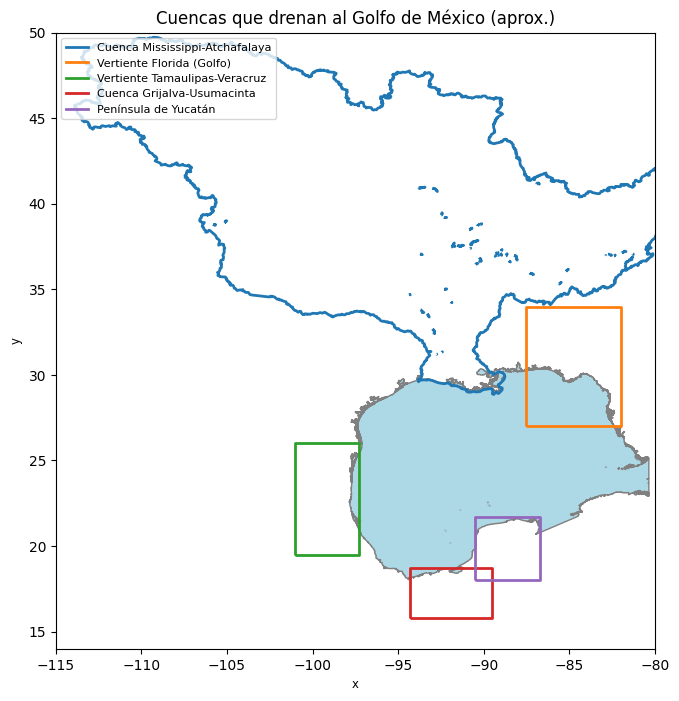

In [68]:
# ===================== PASO 5.1 — CUENCAS =====================
import regionmask
from urllib.parse import urlencode

params = {"where": "huc2 IN ('05','06','07','08','10','11')",
          "outFields": "huc2,name", "returnGeometry": "true", "outSR": "4326",
          "maxAllowableOffset": "0.02", "geometryPrecision": "3", "f": "geojson"}
url_huc2 = ("https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer/1/query?"
            + urlencode(params))
gdf_huc = gpd.read_file(url_huc2)
print(gdf_huc[["huc2", "name"]])
mississippi = shapely.make_valid(shapely.union_all(gdf_huc.geometry.make_valid().array))

# Polígono (Mississippi) o caja aproximada sobre tierra: box(lon_min, lat_min, lon_max, lat_max)
CUENCAS = {
    "Cuenca Mississippi-Atchafalaya":       mississippi,
    "Vertiente Florida (Golfo)":            shapely.box(-87.5, 27.0, -82.0, 34.0),
    "Vertiente Tamaulipas-Veracruz":        shapely.box(-101.0, 19.5, -97.3, 26.0),
    "Cuenca Grijalva-Usumacinta":           shapely.box(-94.3, 15.8, -89.5, 18.7),
    "Península de Yucatán":                 shapely.box(-90.5, 18.0, -86.7, 21.7),
}
PAREJAS = [  # (cuenca, región marina)
    ("Cuenca Mississippi-Atchafalaya", "Pluma Mississippi-Atchafalaya"),
    ("Vertiente Florida (Golfo)",      "Plataforma oeste de Florida"),
    ("Vertiente Tamaulipas-Veracruz",  "Plataforma Tamaulipas-Veracruz"),
    ("Cuenca Grijalva-Usumacinta",     "Bahía de Campeche"),
    ("Península de Yucatán",           "Banco de Campeche (Yucatán)"),
    ("Cuenca Mississippi-Atchafalaya", "Golfo profundo (oceánico)"),   # control
]
BBOX_PP = dict(lon_min=-115.0, lon_max=-80.0, lat_min=14.0, lat_max=50.0)

fig, ax = plt.subplots(figsize=(10, 8))
gpd.GeoSeries([geometria_golfo]).plot(ax=ax, color="lightblue", edgecolor="gray")
for i, (nombre, geom) in enumerate(CUENCAS.items()):
    gpd.GeoSeries([geom]).boundary.plot(ax=ax, color=f"C{i}", lw=2)
    ax.plot([], [], color=f"C{i}", lw=2, label=nombre)
ax.set_xlim(BBOX_PP["lon_min"], BBOX_PP["lon_max"]); ax.set_ylim(BBOX_PP["lat_min"], BBOX_PP["lat_max"])
ax.set_title("Cuencas que drenan al Golfo de México (aprox.)"); ax.legend(fontsize=8, loc="upper left")
plt.show()

In [69]:
# ===================== PASO 5.2 — PRECIPITACIÓN GPM =====================
DIR_SUB["pp"] = BASE / "subsets" / "precipitacion"
DIR_SUB["pp"].mkdir(parents=True, exist_ok=True)

res = earthaccess.search_data(short_name="GPM_3IMERGM", version="07", temporal=(INICIO, FIN))
gran_pp = {}
for g in res:
    for url in g.data_links():
        nombre = url.split("/")[-1]
        m = re.search(r"3IMERG\.(\d{8})-", nombre)
        if m and nombre.upper().endswith(".HDF5"):
            s = m.group(1)
            gran_pp.setdefault(pd.Period(f"{s[:4]}-{s[4:6]}", freq="M"), (g, nombre))
            break
esperados = pd.period_range(INICIO[:7], FIN[:7], freq="M")
print(f"GPM: {len(res)} en catálogo → {len(gran_pp)} meses únicos")
print("Faltantes:", [str(p) for p in esperados if p not in gran_pp])

def recortar_pp(ruta, mes):
    try:
        ds = xr.open_dataset(ruta, group="Grid", engine="h5netcdf", decode_times=False)
    except Exception:
        ds = xr.open_dataset(ruta, group="Grid", engine="netcdf4", decode_times=False)
    with ds:
        p = ds["precipitation"].isel(time=0).transpose("lat", "lon")
        unidades = p.attrs.get("units", "")
        p = p.sel(lat=slice(BBOX_PP["lat_min"], BBOX_PP["lat_max"]),
                  lon=slice(BBOX_PP["lon_min"], BBOX_PP["lon_max"])).load()
    v = p.values.astype("float32")
    if "hr" in unidades:                       # mm/h → mm/mes
        v = v * 24 * mes.days_in_month
    else:
        print("   ¡Revisar unidades!", unidades)
    v[v < 0] = np.nan
    out = xr.DataArray(v[np.newaxis],
                       coords={"time": [mes.to_timestamp()], "lat": p.lat.values, "lon": p.lon.values},
                       dims=("time", "lat", "lon"), name="pp", attrs={"units": "mm/mes"})
    destino = ruta_subset("pp", mes)
    tmp = destino.parent / (destino.name + ".tmp")
    out.to_netcdf(tmp, encoding={"pp": {"zlib": True, "complevel": 4}})
    tmp.replace(destino)

pendientes = [(m, gn) for m, gn in sorted(gran_pp.items()) if not ruta_subset("pp", m).exists()]
print("Pendientes:", len(pendientes))
errores_pp, t0 = [], time.time()
for i in range(0, len(pendientes), 12):
    bloque = pendientes[i:i + 12]
    try:
        earthaccess.download([g for _, (g, _) in bloque], local_path=str(TMP), threads=6)
    except Exception as e:
        errores_pp += [(str(m), repr(e)) for m, _ in bloque]; continue
    for mes, (g, nombre) in bloque:
        try:
            recortar_pp(TMP / nombre, mes)
        except Exception as e:
            errores_pp.append((str(mes), repr(e)))
    for p in TMP.iterdir():
        if p.is_file(): p.unlink()
    print(f"   {min(i + 12, len(pendientes))}/{len(pendientes)} — {(time.time() - t0) / 60:.1f} min")
print("Errores:", len(errores_pp), errores_pp[:5])

GPM: 273 en catálogo → 273 meses únicos
Faltantes: ['2025-10', '2025-11', '2025-12']
Pendientes: 273


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

   12/273 — 0.2 min


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

... (83 outputs left out)

QUEUEING TASKS | :   0%|          | 0/9 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/9 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/9 [00:00<?, ?it/s]

   273/273 — 3.2 min
Errores: 0 []


In [70]:
# ===================== PASO 5.3 — SERIES Y TENDENCIA DE LLUVIA =====================
cubos["pp"] = cargar_cubo("pp")
print("Cubo pp:", dict(cubos["pp"].sizes))

lon2, lat2 = np.meshgrid(cubos["pp"].lon.values, cubos["pp"].lat.values)
tierra = (regionmask.defined_regions.natural_earth_v5_0_0.land_10
          .mask(cubos["pp"].lon, cubos["pp"].lat).notnull().values)
pesos = np.cos(np.deg2rad(cubos["pp"].lat))

tablas = []
for nombre, geom in CUENCAS.items():
    m = shapely.contains_xy(geom, lon2, lat2) & tierra
    mda = xr.DataArray(m, coords={"lat": cubos["pp"].lat, "lon": cubos["pp"].lon}, dims=("lat", "lon"))
    serie = cubos["pp"].where(mda).weighted(pesos).mean(("lat", "lon"))
    tablas.append(pd.DataFrame({"fecha": pd.to_datetime(cubos["pp"].time.values),
                                "cuenca": nombre, "pp": serie.values, "celdas": int(m.sum())}))
pp = pd.concat(tablas, ignore_index=True)
pp["mes"] = pp.fecha.dt.month
pp["anomalia"] = pp.pp - pp.groupby(["cuenca", "mes"]).pp.transform("mean")
pp.to_csv(BASE / "series_precipitacion_cuencas.csv", index=False)

filas = []
for nombre, d in pp.groupby("cuenca"):
    d = d.sort_values("fecha").dropna(subset=["anomalia"])
    t = ((d.fecha - d.fecha.iloc[0]).dt.days / 365.25).values
    y = d.anomalia.values
    hr = mk.hamed_rao_modification_test(y)
    sen, lo, hi = sen_con_ic(t, y, hr.var_s)                   # mm/mes por año
    ols = sm.OLS(y, sm.add_constant(t)).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    anual = d.pp.mean() * 12
    filas.append({"cuenca": nombre, "celdas": d.celdas.iloc[0],
                  "lluvia media (mm/año)": anual,
                  "Sen (mm/año/década)": sen * 120, "IC95 inf": lo * 120, "IC95 sup": hi * 120,
                  "Sen (%/década)": 100 * sen * 120 / anual,
                  "p MK Hamed-Rao": hr.p, "p OLS-HAC": ols.pvalues[1]})
tend_pp = pd.DataFrame(filas).set_index("cuenca")
tend_pp.to_csv(BASE / "tabla_tendencias_precipitacion.csv")
display(tend_pp)

Cubo pp: {'time': 273, 'lat': 360, 'lon': 350}


,celdas,lluvia media (mm/año),Sen (mm/año/década),IC95 inf,IC95 sup,Sen (%/década),p MK Hamed-Rao,p OLS-HAC
cuenca,,,,,,,,
Cuenca Grijalva-Usumacinta,1306,1988,-101.9,-173,-24.12,-5.124,0.0106,0.03509
Cuenca Mississippi-Atchafalaya,34452,904.8,3.944,-29.11,37.77,0.4359,0.8037,0.709
Península de Yucatán,1034,1336,38.52,-24.51,104.6,2.882,0.2426,0.295
Vertiente Florida (Golfo),2397,1449,50.69,-33.94,134.2,3.498,0.2354,0.5321
Vertiente Tamaulipas-Veracruz,2253,825,-26.19,-89.26,33.19,-3.174,0.3915,0.257


Celda 5.4: ¿Los meses más lluviosos traen más clorofila? ¿El agua más caliente trae menos?

Antes de correlacionar quitamos la tendencia lineal de cada serie. Si no, dos variables que solo coinciden en tener tendencia saldrían correlacionadas sin relación real. El valor p usa el n efectivo de Bretherton, para corregir por autocorrelación.

,desfase (meses),r Spearman,p ajustado,n,n efectivo
pareja,,,,,
Cuenca Grijalva-Usumacinta → Bahía de Campeche,1,0.48,0,272,207.1
Cuenca Mississippi-Atchafalaya → Golfo profundo (oceánico),3,0.137,0.029,270,253.2
Cuenca Mississippi-Atchafalaya → Pluma Mississippi-Atchafalaya,2,0.321,0,271,253.6
Península de Yucatán → Banco de Campeche (Yucatán),0,0.055,0.392,273,247.2
Vertiente Florida (Golfo) → Plataforma oeste de Florida,3,0.234,0,270,230.3
Vertiente Tamaulipas-Veracruz → Plataforma Tamaulipas-Veracruz,1,0.24,0,272,241.6


,r Spearman (SST vs chl),p ajustado,n efectivo
region,,,
Golfo completo,-0.463,0,143.5
Pluma Mississippi-Atchafalaya,-0.208,0.005,179.4
Plataforma oeste de Florida,-0.319,0,166.7
Plataforma Tamaulipas-Veracruz,-0.396,0,157.4
Bahía de Campeche,-0.246,0.001,173.7
Banco de Campeche (Yucatán),-0.298,0,169
Golfo profundo (oceánico),-0.415,0,152.9


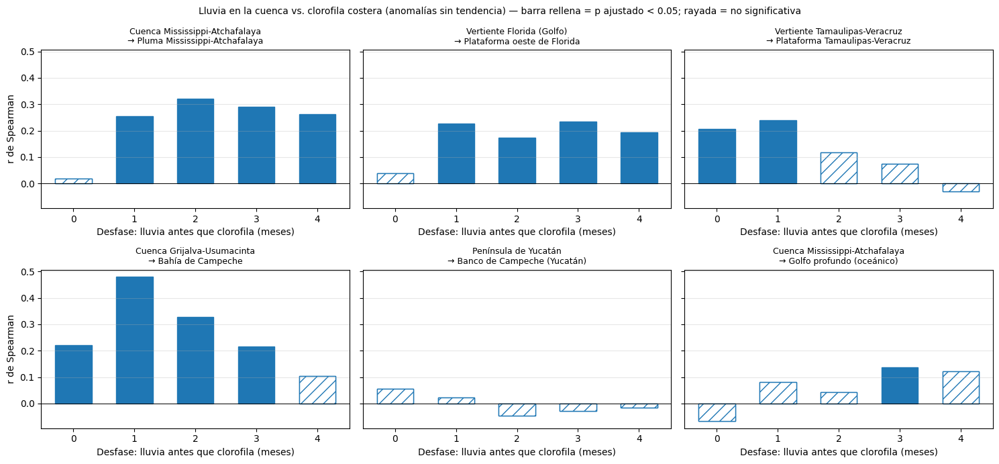

In [71]:
# ===================== PASO 5.4 — CORRELACIONES =====================
from scipy.signal import detrend

an = pd.read_csv(BASE / "series_anomalias.csv", parse_dates=["fecha"])

def corr_ajustada(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    r = stats.spearmanr(x, y)[0]
    rx, ry = pd.Series(x).autocorr(1), pd.Series(y).autocorr(1)
    n = len(x)
    neff = float(np.clip(n * (1 - rx * ry) / (1 + rx * ry), 3, n))
    tt = r * np.sqrt((neff - 2) / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(tt), neff - 2), n, neff

# (a) Lluvia en la cuenca (con desfase de 0 a 4 meses) → clorofila en la región marina
filas = []
for cuenca, region in PAREJAS:
    x = pp[pp.cuenca == cuenca].set_index("fecha").anomalia
    y = an[(an.variable == "chl") & (an.region == region)].set_index("fecha").anomalia
    d = pd.concat({"x": x, "y": y}, axis=1).dropna()
    d["x"], d["y"] = detrend(d.x.values), detrend(d.y.values)
    for lag in range(0, 5):
        r, p, n, neff = corr_ajustada(d.x.shift(lag).values, d.y.values)
        filas.append({"pareja": f"{cuenca} → {region}", "desfase (meses)": lag,
                      "r Spearman": r, "p ajustado": p, "n": n, "n efectivo": neff})
corr_pp = pd.DataFrame(filas)
corr_pp.to_csv(BASE / "correlaciones_lluvia_clorofila.csv", index=False)
display(corr_pp.loc[corr_pp.groupby("pareja")["r Spearman"].apply(lambda s: s.abs().idxmax())]
        .set_index("pareja").round(3))

# (b) SST → clorofila en la misma región (desfase 0)
filas = []
for region in ORDEN:
    x = an[(an.variable == "sst") & (an.region == region)].set_index("fecha").anomalia
    y = an[(an.variable == "chl") & (an.region == region)].set_index("fecha").anomalia
    d = pd.concat({"x": x, "y": y}, axis=1).dropna()
    r, p, n, neff = corr_ajustada(detrend(d.x.values), detrend(d.y.values))
    filas.append({"region": region, "r Spearman (SST vs chl)": r, "p ajustado": p, "n efectivo": neff})
corr_sst = pd.DataFrame(filas).set_index("region").round(3)
corr_sst.to_csv(BASE / "correlaciones_sst_clorofila.csv")
display(corr_sst)

# Gráfica: correlación según el desfase, un panel por pareja
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, (pareja, d) in zip(axes.flat, corr_pp.groupby("pareja", sort=False)):
    sig = d["p ajustado"] < 0.05
    ax.bar(d["desfase (meses)"], d["r Spearman"], color="tab:blue",
           edgecolor="tab:blue", alpha=1.0, width=0.6)
    ax.bar(d["desfase (meses)"][~sig], d["r Spearman"][~sig], color="white",
           edgecolor="tab:blue", width=0.6, hatch="//")
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(pareja.replace(" → ", "\n→ "), fontsize=9)
    ax.set_xlabel("Desfase: lluvia antes que clorofila (meses)")
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel("r de Spearman"); axes[1, 0].set_ylabel("r de Spearman")
fig.suptitle("Lluvia en la cuenca vs. clorofila costera (anomalías sin tendencia) — "
             "barra rellena = p ajustado < 0.05; rayada = no significativa", fontsize=10)
plt.tight_layout(); plt.show()

In [72]:
# ===================== PASO 6.1 — FDR EN CORRELACIONES =====================
corr_pp["q (FDR)"] = multipletests(corr_pp["p ajustado"], method="fdr_bh")[1]
corr_sst["q (FDR)"] = multipletests(corr_sst["p ajustado"], method="fdr_bh")[1]

mejor = corr_pp.loc[corr_pp.groupby("pareja")["r Spearman"].apply(lambda s: s.abs().idxmax())]
display(mejor.set_index("pareja").round(3))
display(corr_sst.round(3))
corr_pp.to_csv(BASE / "correlaciones_lluvia_clorofila.csv", index=False)
corr_sst.to_csv(BASE / "correlaciones_sst_clorofila.csv")

,desfase (meses),r Spearman,p ajustado,n,n efectivo,q (FDR)
pareja,,,,,,
Cuenca Grijalva-Usumacinta → Bahía de Campeche,1,0.48,0,272,207.1,0
Cuenca Mississippi-Atchafalaya → Golfo profundo (oceánico),3,0.137,0.029,270,253.2,0.058
Cuenca Mississippi-Atchafalaya → Pluma Mississippi-Atchafalaya,2,0.321,0,271,253.6,0
Península de Yucatán → Banco de Campeche (Yucatán),0,0.055,0.392,273,247.2,0.535
Vertiente Florida (Golfo) → Plataforma oeste de Florida,3,0.234,0,270,230.3,0.001
Vertiente Tamaulipas-Veracruz → Plataforma Tamaulipas-Veracruz,1,0.24,0,272,241.6,0.001


,r Spearman (SST vs chl),p ajustado,n efectivo,q (FDR)
region,,,,
Golfo completo,-0.463,0,143.5,0
Pluma Mississippi-Atchafalaya,-0.208,0.005,179.4,0.005
Plataforma oeste de Florida,-0.319,0,166.7,0
Plataforma Tamaulipas-Veracruz,-0.396,0,157.4,0
Bahía de Campeche,-0.246,0.001,173.7,0.001
Banco de Campeche (Yucatán),-0.298,0,169,0
Golfo profundo (oceánico),-0.415,0,152.9,0


In [73]:
# ===================== PASO 6.2 — ROBUSTEZ (QUITAR UN AÑO) =====================
def robustez(var, region):
    d = an[(an.variable == var) & (an.region == region)].sort_values("fecha")
    filas = []
    for anio in sorted(d.fecha.dt.year.unique()):
        dd = d[d.fecha.dt.year != anio]
        t = ((dd.fecha - dd.fecha.iloc[0]).dt.days / 365.25).values
        y = dd.anomalia.values
        hr = mk.hamed_rao_modification_test(y)
        sen = sen_con_ic(t, y, hr.var_s)[0] * 10
        if var == "chl":
            sen = (10 ** sen - 1) * 100
        filas.append({"año excluido": anio, "Sen": sen, "p": hr.p})
    r = pd.DataFrame(filas)
    peor = r.loc[r.p.idxmax()]
    return {"region": region, "Sen mín": r.Sen.min(), "Sen máx": r.Sen.max(),
            "p máximo": r.p.max(), "año que más debilita": int(peor["año excluido"]),
            "% de casos con p<0.05": 100 * (r.p < 0.05).mean()}

rob = pd.DataFrame([robustez("chl", reg) for reg in
                    ["Banco de Campeche (Yucatán)", "Pluma Mississippi-Atchafalaya",
                     "Plataforma Tamaulipas-Veracruz", "Golfo profundo (oceánico)",
                     "Plataforma oeste de Florida"]]).set_index("region").round(3)
display(rob)

,Sen mín,Sen máx,p máximo,año que más debilita,% de casos con p<0.05
region,,,,,
Banco de Campeche (Yucatán),-8.083,-5.811,0.084,2021,91.3
Pluma Mississippi-Atchafalaya,3.134,6.93,0.237,2006,39.13
Plataforma Tamaulipas-Veracruz,3.81,6.81,0.233,2006,8.696
Golfo profundo (oceánico),-3.813,-1.527,0.202,2003,21.74
Plataforma oeste de Florida,-4.057,-0.387,0.832,2005,4.348


In [74]:
# ===================== PASO 6.3 — MATRIZ FINAL =====================
def etiqueta(pend, p):
    if p < 0.05:
        return "Aumento significativo" if pend > 0 else "Disminución significativa"
    if p < 0.10:
        return "Aumento marginal" if pend > 0 else "Disminución marginal"
    return "Sin tendencia detectada"

filas = []
for _, r in tend.iterrows():
    esp = resumen_espacial.loc[(r.variable, r.region)]
    if r.variable == "chl":
        s = r["Sen (%/década)"]
        mag = (f"{s:+.1f} %/década (IC95 {r['IC95 inf']:+.1f} a {r['IC95 sup']:+.1f}); "
               f"{r['Sen (mg/m³/década)']:+.4f} mg/m³/década; total {r['Cambio total (%)']:+.1f} %")
    else:
        s = r["Sen (°C/década)"]
        mag = (f"{s:+.2f} °C/década (IC95 {r['IC95 inf']:+.2f} a {r['IC95 sup']:+.2f}); "
               f"total {r['Cambio total (°C)']:+.2f} °C")
    filas.append({"Variable": "Clorofila-a" if r.variable == "chl" else "SST",
                  "Dónde": r.region,
                  "Qué cambia": etiqueta(s, r["p MK Hamed-Rao"]),
                  "Cuánto (Sen)": mag,
                  "p (MK Hamed-Rao)": r["p MK Hamed-Rao"],
                  "p (OLS-HAC)": r["p OLS-HAC"],
                  "q (FDR)": r["q (BH-FDR)"],
                  "% área ↑ signif.": esp["% celdas con aumento significativo"],
                  "% área ↓ signif.": esp["% celdas con disminución significativa"]})
for cuenca, r in tend_pp.iterrows():
    s = r["Sen (mm/año/década)"]
    filas.append({"Variable": "Precipitación", "Dónde": cuenca,
                  "Qué cambia": etiqueta(s, r["p MK Hamed-Rao"]),
                  "Cuánto (Sen)": (f"{s:+.0f} mm/año/década (IC95 {r['IC95 inf']:+.0f} a "
                                   f"{r['IC95 sup']:+.0f}); {r['Sen (%/década)']:+.1f} %/década"),
                  "p (MK Hamed-Rao)": r["p MK Hamed-Rao"], "p (OLS-HAC)": r["p OLS-HAC"]})
matriz = pd.DataFrame(filas)
display(matriz)

with pd.ExcelWriter(BASE / "resultados_golfo_mexico.xlsx") as xw:
    matriz.to_excel(xw, sheet_name="Matriz de tendencias", index=False)
    tend.to_excel(xw, sheet_name="Tendencias detalle", index=False)
    resumen_espacial.to_excel(xw, sheet_name="Distribución espacial")
    tend_pp.to_excel(xw, sheet_name="Precipitación")
    corr_pp.to_excel(xw, sheet_name="Corr lluvia-clorofila", index=False)
    corr_sst.to_excel(xw, sheet_name="Corr SST-clorofila")
    rob.to_excel(xw, sheet_name="Robustez")
print("Guardado en:", BASE / "resultados_golfo_mexico.xlsx")

,Variable,Dónde,Qué cambia,Cuánto (Sen),p (MK Hamed-Rao),p (OLS-HAC),q (FDR),% área ↑ signif.,% área ↓ signif.
0,Clorofila-a,Golfo completo,Sin tendencia detectada,-0.3 %/década (IC95 -2.6 a +1.9); -0.0006 mg/m...,0.8085,0.8286,0.8085,2.48,11.49
1,Clorofila-a,Pluma Mississippi-Atchafalaya,Aumento significativo,+5.3 %/década (IC95 +0.4 a +10.5); +0.0823 mg/...,0.03399,0.2203,0.05288,13.51,0
2,Clorofila-a,Plataforma oeste de Florida,Sin tendencia detectada,-2.8 %/década (IC95 -7.1 a +1.8); -0.0122 mg/m...,0.2175,0.4406,0.2512,1.93,21.74
3,Clorofila-a,Plataforma Tamaulipas-Veracruz,Aumento marginal,+5.4 %/década (IC95 -0.8 a +12.3); +0.0118 mg/...,0.09048,0.0567,0.1152,0.68,0
4,Clorofila-a,Bahía de Campeche,Sin tendencia detectada,+2.6 %/década (IC95 -1.6 a +6.8); +0.0149 mg/m...,0.2332,0.2142,0.2512,4.65,0
5,Clorofila-a,Banco de Campeche (Yucatán),Disminución significativa,-6.7 %/década (IC95 -11.7 a -1.2); -0.0215 mg/...,0.01869,0.02127,0.03271,0,14.6
6,Clorofila-a,Golfo profundo (oceánico),Disminución marginal,-3.0 %/década (IC95 -6.0 a +0.2); -0.0032 mg/m...,0.06591,0.07483,0.09228,0,8.98
7,SST,Golfo completo,Aumento significativo,+0.45 °C/década (IC95 +0.35 a +0.56); total +1...,2.578e-13,6.263e-16,1.805e-12,99.87,0
8,SST,Pluma Mississippi-Atchafalaya,Aumento significativo,+0.45 °C/década (IC95 +0.30 a +0.61); total +1...,8.348e-08,2.784e-07,1.67e-07,98.7,0
9,SST,Plataforma oeste de Florida,Aumento significativo,+0.55 °C/década (IC95 +0.40 a +0.70); total +1...,2.728e-11,2.321e-14,1.273e-10,99.52,0


Guardado en: /content/drive/MyDrive/Proyecto_Golfo_Mexico/resultados_golfo_mexico.xlsx


In [75]:
# ===================== PASO 6.4 — NIVEL DE EVIDENCIA =====================
rob_pct = rob["% de casos con p<0.05"]

def evidencia(r):
    p, q = r["p (MK Hamed-Rao)"], r.get("q (FDR)", np.nan)
    pr = rob_pct.get(r["Dónde"], np.nan) if r["Variable"] == "Clorofila-a" else np.nan
    if p >= 0.10:
        return "Sin tendencia detectada"
    sig_fdr = (q < 0.05) if pd.notna(q) else (p < 0.05)
    robusta = pd.isna(pr) or pr >= 80
    if p < 0.05 and sig_fdr and robusta:
        return "Sólida"
    return "Débil / no robusta (misma dirección, significancia frágil)"

matriz["Nivel de evidencia"] = matriz.apply(evidencia, axis=1)
display(matriz[["Variable", "Dónde", "Qué cambia", "Nivel de evidencia"]])

with pd.ExcelWriter(BASE / "resultados_golfo_mexico.xlsx", mode="a",
                    if_sheet_exists="replace") as xw:
    matriz.to_excel(xw, sheet_name="Matriz de tendencias", index=False)
print("Excel actualizado.")

,Variable,Dónde,Qué cambia,Nivel de evidencia
0,Clorofila-a,Golfo completo,Sin tendencia detectada,Sin tendencia detectada
1,Clorofila-a,Pluma Mississippi-Atchafalaya,Aumento significativo,"Débil / no robusta (misma dirección, significa..."
2,Clorofila-a,Plataforma oeste de Florida,Sin tendencia detectada,Sin tendencia detectada
3,Clorofila-a,Plataforma Tamaulipas-Veracruz,Aumento marginal,"Débil / no robusta (misma dirección, significa..."
4,Clorofila-a,Bahía de Campeche,Sin tendencia detectada,Sin tendencia detectada
5,Clorofila-a,Banco de Campeche (Yucatán),Disminución significativa,Sólida
6,Clorofila-a,Golfo profundo (oceánico),Disminución marginal,"Débil / no robusta (misma dirección, significa..."
7,SST,Golfo completo,Aumento significativo,Sólida
8,SST,Pluma Mississippi-Atchafalaya,Aumento significativo,Sólida
9,SST,Plataforma oeste de Florida,Aumento significativo,Sólida


Excel actualizado.


¿Cuántos años hacen falta para detectar cada tendencia?

La fórmula de Weatherhead et al. (1998) estima cuántos años de datos se necesitan para detectar una tendencia de cierto tamaño, dado el ruido y la autocorrelación de la serie (con 95 % de confianza y 90 % de probabilidad). Así puedes pasar de “no detectada” a “se podría confirmar hacia el año X”.

In [76]:
# ===================== PASO 7 — AÑOS NECESARIOS PARA DETECTAR =====================
an = pd.read_csv(BASE / "series_anomalias.csv", parse_dates=["fecha"])
ORDEN = ["Golfo completo", "Pluma Mississippi-Atchafalaya", "Plataforma oeste de Florida",
         "Plataforma Tamaulipas-Veracruz", "Bahía de Campeche",
         "Banco de Campeche (Yucatán)", "Golfo profundo (oceánico)"]

filas = []
for var in ["chl", "sst"]:
    for reg in ORDEN:
        d = an[(an.variable == var) & (an.region == reg)].sort_values("fecha").dropna(subset=["anomalia"])
        t = ((d.fecha - d.fecha.iloc[0]).dt.days / 365.25).values
        y = d.anomalia.values
        hr = mk.hamed_rao_modification_test(y)
        w0 = sen_con_ic(t, y, hr.var_s)[0]                     # tendencia por año
        ruido = y - (np.median(y - w0 * t) + w0 * t)           # lo que queda sin la tendencia
        sigma = ruido.std(ddof=1)
        phi = pd.Series(ruido).autocorr(1)
        n_req = ((3.3 * sigma / abs(w0)) * np.sqrt((1 + phi) / (1 - phi))) ** (2 / 3)
        filas.append({
            "variable": var, "region": reg,
            "tendencia por década": (10 ** (w0 * 10) - 1) * 100 if var == "chl" else w0 * 10,
            "unidad": "%/década" if var == "chl" else "°C/década",
            "ruido (σ)": sigma, "autocorrelación (φ)": phi,
            "años necesarios": n_req,
            "años disponibles": t[-1],
            "años que faltan": max(0.0, n_req - t[-1]),
            "detectable hacia": int(np.ceil(2003 + n_req)),
        })
weath = pd.DataFrame(filas).set_index(["variable", "region"]).round(2)
weath.to_csv(BASE / "anios_necesarios_weatherhead.csv")
display(weath)

tendencia por década     unidad  \
variable region                                                            
chl      Golfo completo                                 -0.28   %/década   
         Pluma Mississippi-Atchafalaya                   5.26   %/década   
         Plataforma oeste de Florida                    -2.82   %/década   
         Plataforma Tamaulipas-Veracruz                  5.38   %/década   
         Bahía de Campeche                               2.63   %/década   
         Banco de Campeche (Yucatán)                    -6.74   %/década   
         Golfo profundo (oceánico)                         -3   %/década   
sst      Golfo completo                                  0.45  °C/década   
         Pluma Mississippi-Atchafalaya                   0.45  °C/década   
         Plataforma oeste de Florida                     0.55  °C/década   
         Plataforma Tamaulipas-Veracruz                  0.44  °C/década   
         Bahía de Campeche                               0.46  °C/década   
         Banco de Campeche (Yucatán)                     0.53  °C/década   
         Golfo profundo (oceánico)                       0.44  °C/década   

                                         ruido (σ)  autocorrelación (φ)  \
variable region                                                           
chl      Golfo completo                       0.05                 0.61   
         Pluma Mississippi-Atchafalaya        0.12                 0.53   
         Plataforma oeste de Florida          0.08                 0.64   
         Plataforma Tamaulipas-Veracruz        0.1                 0.49   
         Bahía de Campeche                    0.09                 0.48   
         Banco de Campeche (Yucatán)          0.07                 0.55   
         Golfo profundo (oceánico)            0.06                 0.55   
sst      Golfo completo                       0.44                 0.51   
         Pluma Mississippi-Atchafalaya         0.8                  0.4   
         Plataforma oeste de Florida          0.71                 0.39   
         Plataforma Tamaulipas-Veracruz       0.59                 0.55   
         Bahía de Campeche                    0.47                 0.47   
         Banco de Campeche (Yucatán)          0.48                 0.44   
         Golfo profundo (oceánico)            0.44                 0.53   

                                         años necesarios  años disponibles  \
variable region                                                              
chl      Golfo completo                              192             22.92   
         Pluma Mississippi-Atchafalaya             45.65             22.92   
         Plataforma oeste de Florida               57.46             22.92   
         Plataforma Tamaulipas-Veracruz             40.1             22.92   
         Bahía de Campeche                         57.37             22.92   
         Banco de Campeche (Yucatán)               28.32             22.92   
         Golfo profundo (oceánico)                 40.54             22.92   
sst      Golfo completo                            14.65             22.92   
         Pluma Mississippi-Atchafalaya              19.8             22.92   
         Plataforma oeste de Florida               16.06             22.92   
         Plataforma Tamaulipas-Veracruz            18.98             22.92   
         Bahía de Campeche                         14.77             22.92   
         Banco de Campeche (Yucatán)               13.22             22.92   
         Golfo profundo (oceánico)                 15.12             22.92   

                                         años que faltan  detectable hacia  
variable region                                                             
chl      Golfo completo                            169.1              2196  
         Pluma Mississippi-Atchafalaya             22.73              2049  
         Plataforma oeste de Florida               34.54          

¿En qué estación del año ocurren los cambios?

Se calcula la tendencia por separado en cada estación. Así se puede ver, por ejemplo, si el Golfo se calienta más en verano o si la clorofila baja sobre todo en invierno, cuando normalmente es máxima.

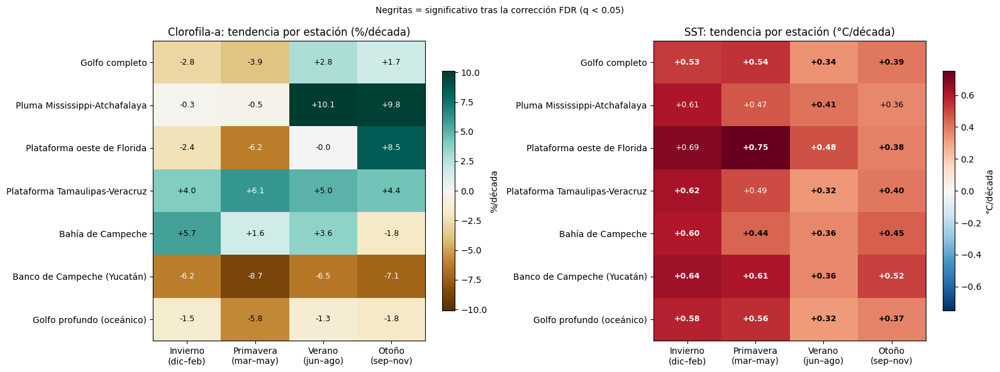

In [77]:
# ===================== PASO 8 — TENDENCIAS POR ESTACIÓN =====================
from matplotlib.colors import TwoSlopeNorm

TEMP = {12: "DEF", 1: "DEF", 2: "DEF", 3: "MAM", 4: "MAM", 5: "MAM",
        6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
NOMBRES = {"DEF": "Invierno\n(dic–feb)", "MAM": "Primavera\n(mar–may)",
           "JJA": "Verano\n(jun–ago)", "SON": "Otoño\n(sep–nov)"}
an["temporada"] = an.fecha.dt.month.map(TEMP)
an["anio_temp"] = an.fecha.dt.year + (an.fecha.dt.month == 12)   # diciembre cuenta con el invierno siguiente
est = (an.groupby(["variable", "region", "temporada", "anio_temp"]).anomalia
         .agg(["mean", "count"]).reset_index())
est = est[est["count"] == 3]                                    # solo temporadas completas

filas = []
for (var, reg, tem), d in est.groupby(["variable", "region", "temporada"]):
    x = d.sort_values("anio_temp")["mean"].values
    r = mk.original_test(x)                                     # valores anuales: poca autocorrelación
    pend = r.slope * 10
    filas.append({"variable": var, "region": reg, "temporada": tem, "n_años": len(x),
                  "tendencia": (10 ** pend - 1) * 100 if var == "chl" else pend, "p": r.p})
tend_est = pd.DataFrame(filas)
tend_est["q (FDR)"] = multipletests(tend_est.p, method="fdr_bh")[1]
tend_est.to_csv(BASE / "tendencias_por_estacion.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, var, unidad, cmap in [(axes[0], "chl", "%/década", "BrBG"), (axes[1], "sst", "°C/década", "RdBu_r")]:
    m = (tend_est[tend_est.variable == var]
         .pivot(index="region", columns="temporada", values="tendencia").loc[ORDEN, list(NOMBRES)])
    q = (tend_est[tend_est.variable == var]
         .pivot(index="region", columns="temporada", values="q (FDR)").loc[ORDEN, list(NOMBRES)])
    lim = np.nanmax(np.abs(m.values))
    im = ax.imshow(m.values, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:+.1f}" if var == "chl" else f"{v:+.2f}",
                    ha="center", va="center", fontsize=9,
                    fontweight="bold" if q.values[i, j] < 0.05 else "normal",
                    color="white" if abs(v) > 0.6 * lim else "black")
    ax.set_xticks(range(4), [NOMBRES[c] for c in m.columns])
    ax.set_yticks(range(len(ORDEN)), ORDEN)
    ax.set_title(("Clorofila-a" if var == "chl" else "SST") + f": tendencia por estación ({unidad})")
    plt.colorbar(im, ax=ax, label=unidad, shrink=0.8)
fig.suptitle("Negritas = significativo tras la corrección FDR (q < 0.05)", fontsize=10)
plt.tight_layout(); plt.show()

¿El cambio fue gradual o hubo un salto?

En las anomalías de SST se veía un salto hacia 2015–2016. La prueba de Pettitt busca el año en que la serie cambia de nivel. Con eso comparamos dos modelos con el criterio BIC:

Línea recta: un cambio gradual.
Escalón: dos niveles, antes y después del año de cambio.

In [78]:
# ===================== PASO 9 — CAMBIO GRADUAL O SALTO =====================
def pettitt(x):
    x = np.asarray(x); n = len(x)
    s = np.sign(x[None, :] - x[:, None])                # s[i, j] = signo(x_j − x_i)
    U = np.array([s[:k + 1, k + 1:].sum() for k in range(n - 1)])
    k = int(np.argmax(np.abs(U))); K = abs(U[k])
    p = min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))
    return k, p                                          # k = último índice antes del cambio

def bic(rss, n, k):
    return n * np.log(rss / n) + k * np.log(n)

anual = (an[an.fecha.dt.year.between(2003, 2025)]
         .groupby(["variable", "region", an.fecha.dt.year.rename("anio")]).anomalia.mean()
         .reset_index())

filas = []
for (var, reg), d in anual.groupby(["variable", "region"]):
    d = d.sort_values("anio"); x = d.anomalia.values; anios = d.anio.values; n = len(x)
    k, p = pettitt(x)
    antes, despues = x[:k + 1].mean(), x[k + 1:].mean()
    rss_esc = ((x[:k + 1] - antes) ** 2).sum() + ((x[k + 1:] - despues) ** 2).sum()
    b = np.polyfit(anios, x, 1); rss_lin = ((x - np.polyval(b, anios)) ** 2).sum()
    dbic = bic(rss_lin, n, 2) - bic(rss_esc, n, 3)       # > 2 favorece escalón; < −2 favorece línea
    salto = (10 ** (despues - antes) - 1) * 100 if var == "chl" else despues - antes
    filas.append({"variable": var, "region": reg, "año de cambio": int(anios[k + 1]),
                  "p Pettitt": p, "salto (después − antes)": salto,
                  "unidad": "%" if var == "chl" else "°C",
                  "ΔBIC (lineal − escalón)": dbic,
                  "modelo preferido": "escalón" if dbic > 2 else ("lineal" if dbic < -2 else "indistinto")})
cambio = pd.DataFrame(filas).set_index(["variable", "region"]).round(3)
cambio.to_csv(BASE / "cambio_de_regimen.csv")
display(cambio)

año de cambio  p Pettitt  \
variable region                                                     
chl      Bahía de Campeche                        2010      0.614   
         Banco de Campeche (Yucatán)              2012      0.044   
         Golfo completo                           2022          1   
         Golfo profundo (oceánico)                2011      0.673   
         Plataforma Tamaulipas-Veracruz           2013      0.557   
         Plataforma oeste de Florida              2006      0.504   
         Pluma Mississippi-Atchafalaya            2008      0.325   
sst      Bahía de Campeche                        2015      0.001   
         Banco de Campeche (Yucatán)              2015      0.001   
         Golfo completo                           2015      0.001   
         Golfo profundo (oceánico)                2015      0.001   
         Plataforma Tamaulipas-Veracruz           2016      0.002   
         Plataforma oeste de Florida              2015      0.001   
         Pluma Mississippi-Atchafalaya            2015      0.003   

                                         salto (después − antes) unidad  \
variable region                                                           
chl      Bahía de Campeche                                 6.924      %   
         Banco de Campeche (Yucatán)                      -11.64      %   
         Golfo completo                                   -2.244      %   
         Golfo profundo (oceánico)                        -5.511      %   
         Plataforma Tamaulipas-Veracruz                    11.56      %   
         Plataforma oeste de Florida                      -17.32      %   
         Pluma Mississippi-Atchafalaya                     17.23      %   
sst      Bahía de Campeche                                 0.633     °C   
         Banco de Campeche (Yucatán)                       0.743     °C   
         Golfo completo                                    0.652     °C   
         Golfo profundo (oceánico)                         0.619     °C   
         Plataforma Tamaulipas-Veracruz                    0.653     °C   
         Plataforma oeste de Florida                        0.78     °C   
         Pluma Mississippi-Atchafalaya                     0.668     °C   

                                         ΔBIC (lineal − escalón)  \
variable region                                                    
chl      Bahía de Campeche                                -1.247   
         Banco de Campeche (Yucatán)                       2.297   
         Golfo completo                                   -2.777   
         Golfo profundo (oceánico)                        -1.447   
         Plataforma Tamaulipas-Veracruz                   -1.231   
         Plataforma oeste de Florida                       8.584   
         Pluma Mississippi-Atchafalaya                     0.711   
sst      Bahía de Campeche                                -1.147   
         Banco de Campeche (Yucatán)                       1.683   
         Golfo completo                                        2   
         Golfo profundo (oceánico)                        -0.343   
         Plataforma Tamaulipas-Veracruz                     1.14   
         Plataforma oeste de Florida                       3.596   
         Pluma Mississippi-Atchafalaya                     1.001   

                                        modelo preferido  
variable region                                           
chl      Bahía de Campeche                    indistinto  
         Banco de Campeche (Yucatán)             escalón  
         Golfo completo                           lineal  
         Golfo profundo (oceánico)            indistinto  
         Plataforma Tamaulipas-Veracruz       indistinto  
         Plataforma oeste de Florida             escalón  
         Pluma Mississippi-Atchafalaya        indistinto  
sst      Bahía de Campeche                    indistinto  
         Banco de Campeche (Yucatán)          indistinto

Paso 10: Regresión múltiple — ¿qué explica la clorofila?

Hasta ahora probamos cada factor por separado. La regresión múltiple los pone juntos:

anomalía de clorofila ~ SST + lluvia (con su desfase) + El Niño (índice ONI) + tiempo

Responde dos preguntas nuevas:

¿Cuánto pesa cada factor cuando se consideran los demás? Los coeficientes estandarizados (β) permiten comparar factores con unidades distintas.
¿Queda tendencia después de descontar la SST, la lluvia y El Niño? Si en el Banco de Campeche el término de tiempo deja de ser significativo, la disminución se “explica” por esos factores. Si sigue, hay otra causa.

ONI cargado: 1950-01-01 a 2026-09-01


,R²,n,tendencia residual (%/década),p tendencia residual
region,,,,
Pluma Mississippi-Atchafalaya,0.22,271,8.686,0.017
Plataforma oeste de Florida,0.26,270,3.339,0.291
Plataforma Tamaulipas-Veracruz,0.228,272,14.48,0
Bahía de Campeche,0.361,272,10.52,0
Banco de Campeche (Yucatán),0.181,273,-0.352,0.911
Golfo profundo (oceánico),0.321,276,3.662,0.087
Golfo completo,0.321,276,5.962,0.001


VIF máximo: 1.59 (menor que 5 = sin problema de colinealidad)


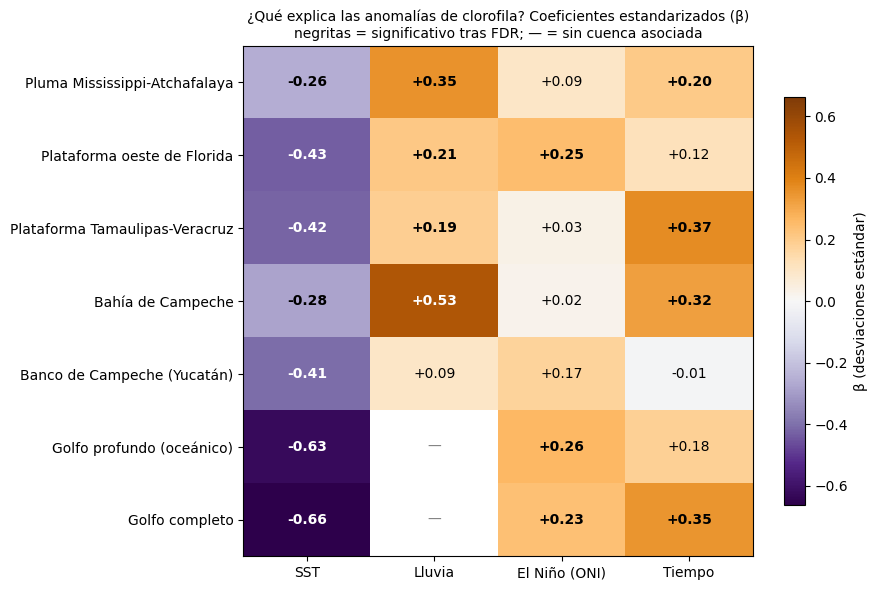

In [79]:
# ===================== PASO 10 — REGRESIÓN MÚLTIPLE =====================
import urllib.request
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Índice ONI de El Niño (NOAA PSL)
try:
    txt = urllib.request.urlopen("https://psl.noaa.gov/data/correlation/oni.data", timeout=30).read().decode()
    reg_oni = {}
    for linea in txt.splitlines():
        partes = linea.split()
        if len(partes) == 13 and partes[0].isdigit():
            for m, v in enumerate(partes[1:], 1):
                if float(v) > -90:
                    reg_oni[pd.Timestamp(int(partes[0]), m, 1)] = float(v)
    oni = pd.Series(reg_oni).sort_index()
    print("ONI cargado:", oni.index.min().date(), "a", oni.index.max().date())
except Exception as e:
    oni = None
    print("No se pudo descargar ONI; el modelo seguirá sin El Niño.", repr(e))

pp = pd.read_csv(BASE / "series_precipitacion_cuencas.csv", parse_dates=["fecha"])
MODELOS = {   # región: (cuenca, desfase en meses)
    "Pluma Mississippi-Atchafalaya":  ("Cuenca Mississippi-Atchafalaya", 2),
    "Plataforma oeste de Florida":    ("Vertiente Florida (Golfo)", 3),
    "Plataforma Tamaulipas-Veracruz": ("Vertiente Tamaulipas-Veracruz", 1),
    "Bahía de Campeche":              ("Cuenca Grijalva-Usumacinta", 1),
    "Banco de Campeche (Yucatán)":    ("Península de Yucatán", 0),
    "Golfo profundo (oceánico)":      (None, None),
    "Golfo completo":                 (None, None),
}
def serie(var, reg):
    return an[(an.variable == var) & (an.region == reg)].set_index("fecha").anomalia.sort_index()

coefs, resumen_mod = [], []
for reg, (cuenca, lag) in MODELOS.items():
    d = pd.DataFrame({"chl": serie("chl", reg), "SST": serie("sst", reg)})
    if cuenca:
        d["Lluvia"] = pp[pp.cuenca == cuenca].set_index("fecha").anomalia.sort_index().shift(lag)
    if oni is not None:
        d["El Niño (ONI)"] = oni
    d = d.dropna()
    d["Tiempo"] = (d.index - d.index[0]).days / 365.25
    z = (d - d.mean()) / d.std()                          # todo en desviaciones estándar
    X = sm.add_constant(z.drop(columns="chl"))
    fit = sm.OLS(z.chl, X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    ic = fit.conf_int()
    for i, c in enumerate(X.columns):
        if c == "const":
            continue
        coefs.append({"region": reg, "predictor": c, "beta": fit.params[c],
                      "IC95 inf": ic.loc[c, 0], "IC95 sup": ic.loc[c, 1], "p": fit.pvalues[c],
                      "VIF": variance_inflation_factor(X.values, i)})
    b_t = fit.params["Tiempo"] * d.chl.std() / d.Tiempo.std()          # log10 por año
    resumen_mod.append({"region": reg, "R²": fit.rsquared, "n": int(fit.nobs),
                        "tendencia residual (%/década)": (10 ** (b_t * 10) - 1) * 100,
                        "p tendencia residual": fit.pvalues["Tiempo"]})

coefs = pd.DataFrame(coefs)
coefs["q (FDR)"] = multipletests(coefs.p, method="fdr_bh")[1]
resumen_mod = pd.DataFrame(resumen_mod).set_index("region").round(3)
coefs.to_csv(BASE / "regresion_coeficientes.csv", index=False)
resumen_mod.to_csv(BASE / "regresion_resumen.csv")
display(resumen_mod)
print("VIF máximo:", round(coefs.VIF.max(), 2), "(menor que 5 = sin problema de colinealidad)")

# Mapa de calor de coeficientes
pred = [p for p in ["SST", "Lluvia", "El Niño (ONI)", "Tiempo"] if p in coefs.predictor.unique()]
B = coefs.pivot(index="region", columns="predictor", values="beta").loc[list(MODELOS), pred]
Q = coefs.pivot(index="region", columns="predictor", values="q (FDR)").loc[list(MODELOS), pred]
lim = np.nanmax(np.abs(B.values))
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(B.values, cmap="PuOr_r", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        v = B.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=10,
                    fontweight="bold" if Q.values[i, j] < 0.05 else "normal",
                    color="white" if abs(v) > 0.6 * lim else "black")
        else:
            ax.text(j, i, "—", ha="center", va="center", color="0.5")
ax.set_xticks(range(len(pred)), pred); ax.set_yticks(range(len(B)), B.index)
ax.set_title("¿Qué explica las anomalías de clorofila? Coeficientes estandarizados (β)\n"
             "negritas = significativo tras FDR; — = sin cuenca asociada", fontsize=10)
plt.colorbar(im, ax=ax, label="β (desviaciones estándar)", shrink=0.8)
plt.tight_layout(); plt.show()

chl listo
sst listo


pendiente (por década)  \
variable region                                                   
chl      Golfo completo                                  -0.278   
         Pluma Mississippi-Atchafalaya                    5.261   
         Plataforma oeste de Florida                     -2.819   
         Plataforma Tamaulipas-Veracruz                   5.378   
         Bahía de Campeche                                2.632   
         Banco de Campeche (Yucatán)                     -6.739   
         Golfo profundo (oceánico)                           -3   
sst      Golfo completo                                   0.453   
         Pluma Mississippi-Atchafalaya                    0.455   
         Plataforma oeste de Florida                       0.55   
         Plataforma Tamaulipas-Veracruz                   0.437   
         Bahía de Campeche                                 0.46   
         Banco de Campeche (Yucatán)                       0.53   
         Golfo profundo (oceánico)                        0.443   

                                         IC95 bootstrap inf  \
variable region                                               
chl      Golfo completo                              -3.592   
         Pluma Mississippi-Atchafalaya               -2.851   
         Plataforma oeste de Florida                 -7.933   
         Plataforma Tamaulipas-Veracruz               -1.75   
         Bahía de Campeche                           -2.282   
         Banco de Campeche (Yucatán)                 -11.91   
         Golfo profundo (oceánico)                   -6.514   
sst      Golfo completo                               0.329   
         Pluma Mississippi-Atchafalaya                0.266   
         Plataforma oeste de Florida                    0.4   
         Plataforma Tamaulipas-Veracruz               0.268   
         Bahía de Campeche                            0.309   
         Banco de Campeche (Yucatán)                  0.402   
         Golfo profundo (oceánico)                    0.322   

                                         IC95 bootstrap sup  P(tendencia > 0)  \
variable region                                                                 
chl      Golfo completo                                3.57             0.423   
         Pluma Mississippi-Atchafalaya                13.65             0.896   
         Plataforma oeste de Florida                  2.311             0.139   
         Plataforma Tamaulipas-Veracruz               12.69             0.911   
         Bahía de Campeche                            7.545             0.865   
         Banco de Campeche (Yucatán)                 -1.506             0.005   
         Golfo profundo (oceánico)                    0.511             0.049   
sst      Golfo completo                               0.582                 1   
         Pluma Mississippi-Atchafalaya                0.659                 1   
         Plataforma oeste de Florida                  0.693                 1   
         Plataforma Tamaulipas-Veracruz                0.61                 1   
         Bahía de Campeche                             0.59                 1   
         Banco de Campeche (Yucatán)                  0.665                 1   
         Golfo profundo (oceánico)                    0.585                 1   

                                         P(tendencia < 0)  
variable region                                            
chl      Golfo completo                             0.577  
         Pluma Mississippi-Atchafalaya              0.104  
         Plataforma oeste de Florida                0.861  
         Plataforma Tamaulipas-Veracruz             0.089  
         Bahía de Campeche                          0.135  
         Banco de Campeche (Yucatán)                0.995  
         Golfo profundo (oceánico)                  0.951  
sst      Golfo completo                                 0  
         Pluma Mississippi-Atchafalaya                  0  
  

evento  \
variable region                                                               
sst      Golfo completo                              mes muy cálido (> p90)   
         Pluma Mississippi-Atchafalaya               mes muy cálido (> p90)   
         Plataforma oeste de Florida                 mes muy cálido (> p90)   
         Plataforma Tamaulipas-Veracruz              mes muy cálido (> p90)   
         Bahía de Campeche                           mes muy cálido (> p90)   
         Banco de Campeche (Yucatán)                 mes muy cálido (> p90)   
         Golfo profundo (oceánico)                   mes muy cálido (> p90)   
chl      Golfo completo                  mes con muy poca clorofila (< p10)   
         Pluma Mississippi-Atchafalaya   mes con muy poca clorofila (< p10)   
         Plataforma oeste de Florida     mes con muy poca clorofila (< p10)   
         Plataforma Tamaulipas-Veracruz  mes con muy poca clorofila (< p10)   
         Bahía de Campeche               mes con muy poca clorofila (< p10)   
         Banco de Campeche (Yucatán)     mes con muy poca clorofila (< p10)   
         Golfo profundo (oceánico)       mes con muy poca clorofila (< p10)   

                                         frecuencia 2003–2012 (%)  \
variable region                                                     
sst      Golfo completo                                        10   
         Pluma Mississippi-Atchafalaya                         10   
         Plataforma oeste de Florida                           10   
         Plataforma Tamaulipas-Veracruz                        10   
         Bahía de Campeche                                     10   
         Banco de Campeche (Yucatán)                           10   
         Golfo profundo (oceánico)                             10   
chl      Golfo completo                                        10   
         Pluma Mississippi-Atchafalaya                         10   
         Plataforma oeste de Florida                           10   
         Plataforma Tamaulipas-Veracruz                        10   
         Bahía de Campeche                                     10   
         Banco de Campeche (Yucatán)                           10   
         Golfo profundo (oceánico)                             10   

                                         frecuencia 2016–2025 (%)  \
variable region                                                     
sst      Golfo completo                                     60.83   
         Pluma Mississippi-Atchafalaya                      34.17   
         Plataforma oeste de Florida                         42.5   
         Plataforma Tamaulipas-Veracruz                     55.83   
         Bahía de Campeche                                  59.17   
         Banco de Campeche (Yucatán)                           70   
         Golfo profundo (oceánico)                           52.5   
chl      Golfo completo                                     3.333   
         Pluma Mississippi-Atchafalaya                      6.667   
         Plataforma oeste de Florida                        3.333   
         Plataforma Tamaulipas-Veracruz                     5.833   
         Bahía de Campeche                                  8.333   
         Banco de Campeche (Yucatán)                        36.67   
         Golfo profundo (oceánico)                          11.67   

                                         prob. modelada 2003 (%)  \
variable region                                                    
sst      Golfo completo                                    2.663   
         Pluma Mississippi-Atchafalaya                     3.986   
         Plataforma oeste de Florida                       5.335   
         Plataforma Tamaulipas-Veracruz                    3.328   
         Bahía de Campeche                                 3.158   
         Banco de Campeche (Yucatán)                       4.897   
         Golfo profundo (oceánico)                

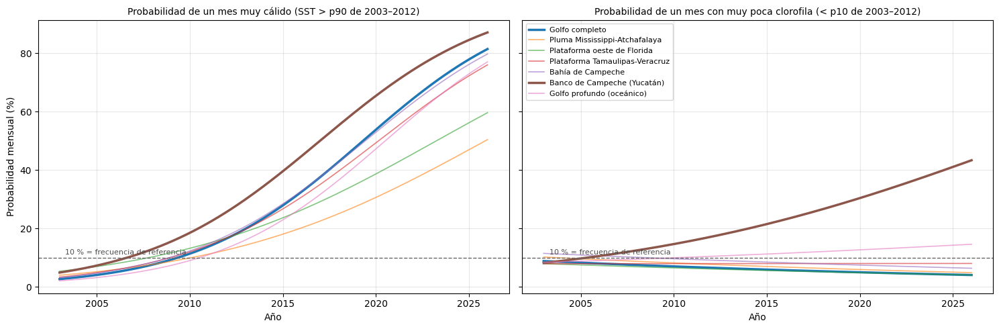

In [80]:
# ===================== PASO 11 — PROBABILIDADES =====================
rng = np.random.default_rng(42)

def sen_rapido(t, y):
    i, j = np.triu_indices(len(y), k=1)
    return np.median((y[j] - y[i]) / (t[j] - t[i]))

def bootstrap_bloques(t, y, B=1000, bloque=12):
    b0 = sen_rapido(t, y)
    a0 = np.median(y - b0 * t)
    res = y - (a0 + b0 * t)
    n = len(y); nb = int(np.ceil(n / bloque))
    pendientes = np.empty(B)
    for k in range(B):
        inicios = rng.integers(0, n - bloque + 1, nb)
        r = np.concatenate([res[s:s + bloque] for s in inicios])[:n]
        pendientes[k] = sen_rapido(t, a0 + b0 * t + r)
    return b0, pendientes

filas = []
for var in ["chl", "sst"]:
    for reg in ORDEN:
        s = serie(var, reg).dropna()
        t = ((s.index - s.index[0]).days / 365.25).values
        b0, bs = bootstrap_bloques(t, s.values)
        conv = (lambda b: (10 ** (b * 10) - 1) * 100) if var == "chl" else (lambda b: b * 10)
        filas.append({"variable": var, "region": reg,
                      "pendiente (por década)": conv(b0),
                      "IC95 bootstrap inf": conv(np.percentile(bs, 2.5)),
                      "IC95 bootstrap sup": conv(np.percentile(bs, 97.5)),
                      "P(tendencia > 0)": (bs > 0).mean(),
                      "P(tendencia < 0)": (bs < 0).mean()})
    print(f"{var} listo")
boot = pd.DataFrame(filas).set_index(["variable", "region"]).round(3)
boot.to_csv(BASE / "bootstrap_probabilidad_direccion.csv")
display(boot)

# B. Probabilidad de meses extremos (regresión logística)
def prob_extremos(var, reg):
    s = serie(var, reg).dropna()
    base = s[s.index.year <= 2012]
    if var == "sst":
        evento = (s > base.quantile(0.9)).astype(int)        # mes muy cálido
    else:
        evento = (s < base.quantile(0.1)).astype(int)        # mes con muy poca clorofila
    t = (s.index.year + (s.index.month - 0.5) / 12 - 2003).values
    X = sm.add_constant(pd.Series(t, index=s.index, name="t"))
    m = sm.GLM(evento, X, family=sm.families.Binomial()).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    p_ini, p_fin = m.predict(np.array([[1.0, 0.0], [1.0, t.max()]]))
    return {"variable": var, "region": reg,
            "evento": "mes muy cálido (> p90)" if var == "sst" else "mes con muy poca clorofila (< p10)",
            "frecuencia 2003–2012 (%)": 100 * evento[s.index.year <= 2012].mean(),
            "frecuencia 2016–2025 (%)": 100 * evento[s.index.year >= 2016].mean(),
            "prob. modelada 2003 (%)": 100 * p_ini,
            "prob. modelada 2025 (%)": 100 * p_fin,
            "razón de momios por década": np.exp(10 * m.params["t"]),
            "p": m.pvalues["t"], "modelo": m, "t": t}

ext = [prob_extremos(v, r) for v in ["sst", "chl"] for r in ORDEN]
extremos = pd.DataFrame([{k: v for k, v in e.items() if k not in ("modelo", "t")} for e in ext])
extremos["q (FDR)"] = multipletests(extremos.p, method="fdr_bh")[1]
extremos = extremos.set_index(["variable", "region"]).round(3)
extremos.to_csv(BASE / "probabilidad_meses_extremos.csv")
display(extremos)

# Gráfica: probabilidad modelada de un mes extremo, 2003–2025
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
tt = np.linspace(0, 23, 200)
for ax, var, titulo in [(axes[0], "sst", "Probabilidad de un mes muy cálido (SST > p90 de 2003–2012)"),
                        (axes[1], "chl", "Probabilidad de un mes con muy poca clorofila (< p10 de 2003–2012)")]:
    for i, e in enumerate([e for e in ext if e["variable"] == var]):
        p = e["modelo"].predict(np.column_stack([np.ones_like(tt), tt]))
        destacada = e["region"] in ("Golfo completo", "Banco de Campeche (Yucatán)")
        ax.plot(2003 + tt, 100 * p, lw=2.5 if destacada else 1.2,
                color=f"C{i}", alpha=1 if destacada else 0.6, label=e["region"])
    ax.axhline(10, color="0.4", ls="--", lw=1)
    ax.text(2003.3, 11, "10 % = frecuencia de referencia", fontsize=8, color="0.3")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Año"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Probabilidad mensual (%)")
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

,tendencia total (%/déc),aporte SST,aporte Lluvia,aporte El Niño (ONI),residual (otros factores)
region,,,,,
Pluma Mississippi-Atchafalaya,5.71,-3.5,0.44,0.35,8.69
Plataforma oeste de Florida,-1.25,-5.34,0.32,0.62,3.34
Plataforma Tamaulipas-Veracruz,6.62,-6.49,-0.5,0.1,14.48
Bahía de Campeche,3,-4.52,-2.45,0.06,10.52
Banco de Campeche (Yucatán),-6.03,-6.21,0.19,0.36,-0.35
Golfo profundo (oceánico),-2.96,-6.68,NaN,0.32,3.66
Golfo completo,-0.32,-6.15,NaN,0.23,5.96


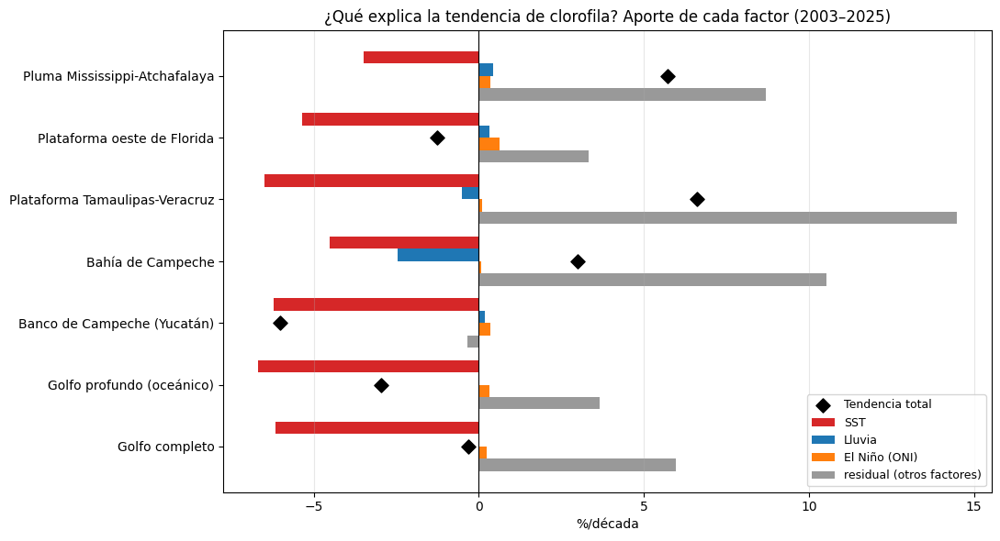

In [82]:
# ===================== PASO 10b — ATRIBUCIÓN DE LA TENDENCIA =====================
def armar(reg):
    cuenca, lag = MODELOS[reg]
    d = pd.DataFrame({"chl": serie("chl", reg), "SST": serie("sst", reg)})
    if cuenca:
        d["Lluvia"] = pp[pp.cuenca == cuenca].set_index("fecha").anomalia.sort_index().shift(lag)
    if oni is not None:
        d["El Niño (ONI)"] = oni
    d = d.dropna()
    d["Tiempo"] = (d.index - d.index[0]).days / 365.25
    return d

pct = lambda b: (10 ** b - 1) * 100
filas = []
for reg in MODELOS:
    d = armar(reg)
    X = sm.add_constant(d.drop(columns="chl"))
    fit = sm.OLS(d.chl, X).fit()
    fila = {"region": reg, "tendencia total (%/déc)": pct(np.polyfit(d.Tiempo, d.chl, 1)[0] * 10)}
    for c in ["SST", "Lluvia", "El Niño (ONI)"]:
        if c in d:
            cambio_c = np.polyfit(d.Tiempo, d[c], 1)[0] * 10          # cuánto cambió el factor por década
            fila[f"aporte {c}"] = pct(fit.params[c] * cambio_c)
        else:
            fila[f"aporte {c}"] = np.nan
    fila["residual (otros factores)"] = pct(fit.params["Tiempo"] * 10)
    filas.append(fila)
atrib = pd.DataFrame(filas).set_index("region").round(2)
atrib.to_csv(BASE / "atribucion_tendencia_clorofila.csv")
display(atrib)

# Gráfica: aporte de cada factor a la tendencia de clorofila
comp = ["aporte SST", "aporte Lluvia", "aporte El Niño (ONI)", "residual (otros factores)"]
colores = ["tab:red", "tab:blue", "tab:orange", "0.6"]
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(atrib)); h = 0.2
for k, (c, col) in enumerate(zip(comp, colores)):
    ax.barh(y + (k - 1.5) * h, atrib[c].fillna(0), height=h, color=col, label=c.replace("aporte ", ""))
ax.scatter(atrib["tendencia total (%/déc)"], y, marker="D", s=60, color="k", zorder=3, label="Tendencia total")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y, atrib.index); ax.invert_yaxis()
ax.set_xlabel("%/década")
ax.set_title("¿Qué explica la tendencia de clorofila? Aporte de cada factor (2003–2025)")
ax.legend(fontsize=9, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

Paso 12: Validación — ¿la clorofila es real o un efecto del sensor?

In [81]:
# ===================== PASO 12.1 — nFLH Y VIIRS =====================
PRODUCTOS_EXTRA = {
    "flh":   dict(short_name="MODISA_L3m_FLH", version="2022.0", patron="*.MO.FLH.nflh.4km*",
                  var_nc="nflh", rango=(-0.1, 5.0)),
    "viirs": dict(short_name="VIIRSN_L3m_CHL", version="2022.0", patron="*.MO.CHL.chlor_a.4km*",
                  var_nc="chlor_a", rango=(0.001, 100.0)),
}
ref = cubos["chl"] if "chl" in cubos else xr.open_dataarray(BASE / "cubo_chl_2003_2025.nc").load()
for k in PRODUCTOS_EXTRA:
    DIR_SUB[k] = BASE / "subsets" / k
    DIR_SUB[k].mkdir(parents=True, exist_ok=True)

gran_extra = {}
for k, cfg in PRODUCTOS_EXTRA.items():
    gran_extra[k] = buscar_mensuales(cfg["short_name"], cfg["version"], cfg["patron"])
    if not gran_extra[k]:
        print(f"   ¡{k}: 0 resultados! Colecciones parecidas:")
        for c in earthaccess.search_datasets(keyword=cfg["short_name"].split("_")[0] + " L3m", count=10):
            print("     ", c.summary()["short-name"], c.summary()["version"])
# Nota: VIIRS empieza en 2012, así que los "faltantes" de 2003–2011 son normales.

def recortar_extra(ruta, clave, mes):
    cfg = PRODUCTOS_EXTRA[clave]
    with xr.open_dataset(ruta) as ds:
        da = ds[cfg["var_nc"]].sel(lat=slice(BBOX["lat_max"], BBOX["lat_min"]),
                                   lon=slice(BBOX["lon_min"], BBOX["lon_max"])).load()
    lo, hi = cfg["rango"]
    da = da.where((da >= lo) & (da <= hi)).sortby("lat", ascending=False).sortby("lon")
    da = da.reindex(lat=ref.lat, lon=ref.lon, method="nearest", tolerance=0.02)   # misma rejilla que chl
    out = xr.DataArray(da.values[np.newaxis].astype("float32"),
                       coords={"time": [mes.to_timestamp()], "lat": ref.lat.values, "lon": ref.lon.values},
                       dims=("time", "lat", "lon"), name=clave)
    destino = ruta_subset(clave, mes)
    tmp = destino.parent / (destino.name + ".tmp")
    out.to_netcdf(tmp, encoding={clave: {"zlib": True, "complevel": 4}})
    tmp.replace(destino)

for clave, por_mes in gran_extra.items():
    pendientes = [(m, g) for m, g in sorted(por_mes.items()) if not ruta_subset(clave, m).exists()]
    print(f"[{clave}] pendientes: {len(pendientes)}")
    errores, t0 = [], time.time()
    for i in range(0, len(pendientes), 12):
        bloque = pendientes[i:i + 12]
        try:
            earthaccess.download([g for _, g in bloque], local_path=str(TMP), threads=6)
        except Exception as e:
            errores += [(str(m), repr(e)) for m, _ in bloque]; continue
        for mes, g in bloque:
            try:
                recortar_extra(TMP / nombre_archivo(g), clave, mes)
            except Exception as e:
                errores.append((str(mes), repr(e)))
        for p in TMP.iterdir():
            if p.is_file(): p.unlink()
        print(f"   {min(i + 12, len(pendientes))}/{len(pendientes)} — {(time.time() - t0) / 60:.1f} min")
    print(f"[{clave}] errores: {len(errores)}", errores[:5])

MODISA_L3m_FLH: 329 en catálogo → 276 meses únicos
   Faltantes: ninguno
   Ejemplo: AQUA_MODIS.20030101_20030131.L3m.MO.FLH.nflh.4km.nc
VIIRSN_L3m_CHL: 168 en catálogo → 168 meses únicos
   Faltantes: ['2003-01', '2003-02', '2003-03', '2003-04', '2003-05', '2003-06', '2003-07', '2003-08', '2003-09', '2003-10', '2003-11', '2003-12', '2004-01', '2004-02', '2004-03', '2004-04', '2004-05', '2004-06', '2004-07', '2004-08', '2004-09', '2004-10', '2004-11', '2004-12', '2005-01', '2005-02', '2005-03', '2005-04', '2005-05', '2005-06', '2005-07', '2005-08', '2005-09', '2005-10', '2005-11', '2005-12', '2006-01', '2006-02', '2006-03', '2006-04', '2006-05', '2006-06', '2006-07', '2006-08', '2006-09', '2006-10', '2006-11', '2006-12', '2007-01', '2007-02', '2007-03', '2007-04', '2007-05', '2007-06', '2007-07', '2007-08', '2007-09', '2007-10', '2007-11', '2007-12', '2008-01', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06', '2008-07', '2008-08', '2008-09', '2008-10', '2008-11', '2008-12', '2009

QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

   12/276 — 0.2 min


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

... (139 outputs left out)

QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

   168/168 — 2.3 min
[viirs] errores: 0 []


In [83]:
# ===================== PASO 12.2 — COMPARACIÓN =====================
cubos_extra = {k: cargar_cubo(k) for k in PRODUCTOS_EXTRA}
for k, c in cubos_extra.items():
    print(k, dict(c.sizes))

pesos = np.cos(np.deg2rad(ref.lat))
masc = mascaras_regiones(ref)

def serie_regional(cubo, log, m, cobertura_min=25):
    datos = cubo.where(m)
    if log:
        datos = np.log10(datos)
    s = datos.weighted(pesos).mean(("lat", "lon")).to_series()
    cob = 100 * datos.notnull().sum(("lat", "lon")).to_series() / int(m.sum())
    s[cob < cobertura_min] = np.nan
    return s

def anomalia(s):
    return s - s.groupby(s.index.month).transform("mean")

def sen_p(s):
    s = s.dropna()
    t = ((s.index - s.index[0]).days / 365.25).values
    hr = mk.hamed_rao_modification_test(s.values)
    return sen_con_ic(t, s.values, hr.var_s)[0] * 10, hr.p     # por década

pct = lambda b: (10 ** b - 1) * 100
filas = []
for reg, m in masc.items():
    chl = serie_regional(cubos["chl"] if "chl" in cubos else ref, True, m)
    flh = serie_regional(cubos_extra["flh"], False, m)
    vii = serie_regional(cubos_extra["viirs"], True, m)

    b_chl, p_chl = sen_p(anomalia(chl))
    b_flh, p_flh = sen_p(anomalia(flh))
    a_chl, a_flh = anomalia(chl), anomalia(flh)
    ok = a_chl.notna() & a_flh.notna()
    r_cf = stats.spearmanr(a_chl[ok], a_flh[ok])[0]

    chl_c, vii_c = chl["2012":"2025"], vii["2012":"2025"]          # periodo común, anomalías propias
    b_mc, p_mc = sen_p(anomalia(chl_c))
    b_vc, p_vc = sen_p(anomalia(vii_c))
    a_m, a_v = anomalia(chl_c), anomalia(vii_c)
    ok2 = a_m.notna() & a_v.notna()
    r_mv = stats.spearmanr(a_m[ok2], a_v[ok2])[0]

    filas.append({
        "region": reg,
        "chl MODIS 2003–25 (%/déc)": pct(b_chl), "p chl": p_chl,
        "nFLH 2003–25 (%/déc)": 100 * b_flh / flh.mean(), "p nFLH": p_flh,
        "r anomalías chl–nFLH": r_cf,
        "chl MODIS 2012–25 (%/déc)": pct(b_mc), "p MODIS 12–25": p_mc,
        "chl VIIRS 2012–25 (%/déc)": pct(b_vc), "p VIIRS 12–25": p_vc,
        "r anomalías MODIS–VIIRS": r_mv,
        "¿mismo signo nFLH?": np.sign(b_chl) == np.sign(b_flh),
        "¿mismo signo VIIRS?": np.sign(b_mc) == np.sign(b_vc),
    })
valid = pd.DataFrame(filas).set_index("region").round(3)
valid.to_csv(BASE / "validacion_nflh_viirs.csv")
display(valid)

flh {'time': 276, 'lat': 312, 'lon': 432}
viirs {'time': 168, 'lat': 312, 'lon': 432}


,chl MODIS 2003–25 (%/déc),p chl,nFLH 2003–25 (%/déc),p nFLH,r anomalías chl–nFLH,chl MODIS 2012–25 (%/déc),p MODIS 12–25,chl VIIRS 2012–25 (%/déc),p VIIRS 12–25,r anomalías MODIS–VIIRS,¿mismo signo nFLH?,¿mismo signo VIIRS?
region,,,,,,,,,,,,
Golfo completo,-0.278,0.809,1.362,0.746,0.377,4.734,0.262,-2.031,0.412,0.898,False,False
Pluma Mississippi-Atchafalaya,5.261,0.034,2.167,0.287,0.406,10.85,0.233,0.625,0.936,0.951,True,True
Plataforma oeste de Florida,-2.819,0.218,-1.978,0.672,0.613,0.27,0.946,-6.036,0.131,0.955,True,False
Plataforma Tamaulipas-Veracruz,5.378,0.09,6.91,0.126,0.432,10.76,0.27,0.9,0.903,0.951,True,True
Bahía de Campeche,2.632,0.233,6.076,0.085,0.547,4.225,0.293,-2.559,0.505,0.944,True,False
Banco de Campeche (Yucatán),-6.739,0.019,-4.098,0.414,0.762,-1.603,0.798,-6.677,0.249,0.96,True,True
Golfo profundo (oceánico),-3,0.066,0.075,0.991,0.373,3.886,0.335,-1.772,0.228,0.933,False,False


,deriva MODIS−VIIRS (%/déc),deriva IC95 inf,deriva IC95 sup,p deriva,chl MODIS sola 2003–25,p MODIS,chl combinada 2003–25,comb IC95 inf,comb IC95 sup,p combinada,q combinada (FDR)
region,,,,,,,,,,,
Golfo completo,6.758,4.203,9.408,0,-0.278,0.809,-4.71,-5.468,-3.938,0,0
Pluma Mississippi-Atchafalaya,10.04,6.476,13.77,0,5.261,0.034,-0.621,-5.76,4.731,0.806,0.886
Plataforma oeste de Florida,7.695,5.267,10.17,0,-2.819,0.218,-7.399,-11.5,-3.074,0.001,0.003
Plataforma Tamaulipas-Veracruz,9.071,5.504,12.47,0,5.378,0.09,-0.427,-5.932,5.409,0.886,0.886
Bahía de Campeche,7.087,3.54,10.75,0,2.632,0.233,-2.486,-6.952,2.256,0.292,0.408
Banco de Campeche (Yucatán),5.889,3.359,8.532,0,-6.739,0.019,-10.61,-16.06,-4.573,0.002,0.003
Golfo profundo (oceánico),5.113,2.234,7.894,0.001,-3,0.066,-6.531,-8.639,-4.32,0,0


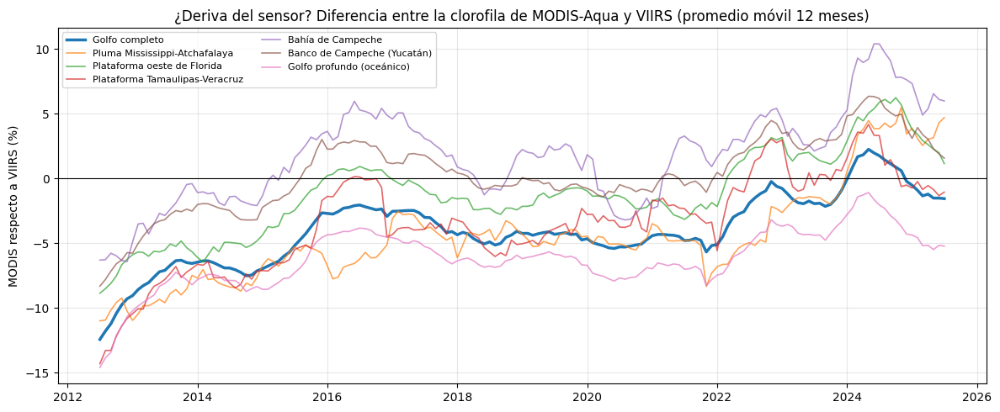

In [84]:
# ===================== PASO 12b — DERIVA Y SERIE COMBINADA =====================
def sen_ic_p(s):
    s = s.dropna()
    t = ((s.index - s.index[0]).days / 365.25).values
    hr = mk.hamed_rao_modification_test(s.values)
    b, lo, hi = sen_con_ic(t, s.values, hr.var_s)
    return pct(b * 10), pct(lo * 10), pct(hi * 10), hr.p

filas, difs, combinadas = [], {}, {}
for reg, m in masc.items():
    chl = serie_regional(cubos["chl"] if "chl" in cubos else ref, True, m)
    vii = serie_regional(cubos_extra["viirs"], True, m)

    dif = (chl - vii)["2012":"2025"].dropna()                     # log10(MODIS / VIIRS)
    difs[reg] = dif
    d_b, d_lo, d_hi, d_p = sen_ic_p(dif)

    offset = (chl - vii)["2012":"2014"].mean()                    # nivel MODIS en el traslape inicial
    comb = pd.concat([chl[:"2011-12"], (vii + offset)["2012":]]).sort_index()
    combinadas[reg] = comb
    c_b, c_lo, c_hi, c_p = sen_ic_p(anomalia(comb))
    m_b, _, _, m_p = sen_ic_p(anomalia(chl))

    filas.append({"region": reg,
                  "deriva MODIS−VIIRS (%/déc)": d_b, "deriva IC95 inf": d_lo, "deriva IC95 sup": d_hi,
                  "p deriva": d_p,
                  "chl MODIS sola 2003–25": m_b, "p MODIS": m_p,
                  "chl combinada 2003–25": c_b, "comb IC95 inf": c_lo, "comb IC95 sup": c_hi,
                  "p combinada": c_p})
deriva = pd.DataFrame(filas).set_index("region")
deriva["q combinada (FDR)"] = multipletests(deriva["p combinada"], method="fdr_bh")[1]
deriva = deriva.round(3)
deriva.to_csv(BASE / "deriva_y_serie_combinada.csv")
display(deriva)

# Gráfica: diferencia MODIS − VIIRS en el tiempo (promedio móvil de 12 meses)
fig, ax = plt.subplots(figsize=(12, 5))
for i, (reg, dif) in enumerate(difs.items()):
    y = (10 ** dif.rolling(12, center=True).mean() - 1) * 100
    ax.plot(y.index, y, lw=2.5 if reg == "Golfo completo" else 1.2,
            alpha=1 if reg == "Golfo completo" else 0.7, color=f"C{i}", label=reg)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("MODIS respecto a VIIRS (%)")
ax.set_title("¿Deriva del sensor? Diferencia entre la clorofila de MODIS-Aqua y VIIRS (promedio móvil 12 meses)")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()